<a href="https://colab.research.google.com/github/shijaalive-cloud/passangers/blob/main/airline_passengers_forecasting_main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Time Series Forecasting: Airline Passengers Dataset

---

### What is this notebook about?

This notebook walks you through the **full lifecycle** of a time series forecasting project using the classic **Airline Passengers dataset**. We will:

1. **Explore** the data visually and statistically
2. **Prepare** the data for different types of models
3. **Train** four different forecasting models:
   - XGBoost (gradient boosting with engineered features)
   - ARIMA (classical statistical model)
   - Simple RNN (basic recurrent neural network)
   - LSTM (long short-term memory network)
4. **Compare** models and draw practical conclusions



# Section 1: Setup and Data Loading

---
##  Key Definitions


**Time Series**: A sequence of data points collected at successive, equally-spaced points in time. Example: monthly sales, daily temperature, stock prices.

**Datetime Index**: Using actual dates/times as the row labels of a DataFrame, instead of integers (0, 1, 2, …). This allows powerful time-based operations like resampling and slicing by date range.

**Tabular Data**: Traditional flat data where each row is an independent observation (e.g., a single customer record). No inherent order between rows.

**Sequence Data**:Data where *order matters*. Each observation depends on previous ones. Time series is a classic example — yesterday's passenger count influences today's prediction.

---

In this section we import all required libraries and load the dataset.

In [ ]:
!pip install pmdarima #Library for auto arima
!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 9.7 MB/s eta 0:00:00


In [ ]:
# Standard library imports
import warnings
warnings.filterwarnings('ignore')          # suppress noisy deprecation warnings

import numpy as np
import pandas as pd                        # data manipulation
import matplotlib.pyplot as plt            # base plotting library
import matplotlib.dates as mdates
import seaborn as sns                      # statistical visualisation
from scipy import stats                    # statistical tests and distributions

# Statsmodels (classical statistics)
from statsmodels.tsa.seasonal import seasonal_decompose   # decompose trend/seasonal/residual
from statsmodels.tsa.stattools import adfuller             # Augmented Dickey-Fuller test
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf  # ACF / PACF plots
from statsmodels.tsa.arima.model import ARIMA              # ARIMA model

# pmdarima – automatic ARIMA order selection
from pmdarima import auto_arima

# Exponential smoothing baselines
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing

# Scikit-learn
from sklearn.preprocessing import MinMaxScaler             # scale features to [0,1]
from sklearn.metrics import mean_absolute_error, mean_squared_error  # evaluation metrics

# XGBoost
from xgboost import XGBRegressor

# TensorFlow / Keras (deep learning)
import tensorflow as tf
from tensorflow.keras.models import Sequential             # stack layers one-by-one
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense # layer types we will use
from tensorflow.keras.callbacks import EarlyStopping       # stop training when val_loss stops improving

# Reproducibility seeds
# Setting seeds ensures you get the same results every time you run the notebook.
np.random.seed(42)
tf.random.set_seed(42)

# Plot style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (14, 5)   # default figure size for all plots
plt.rcParams['font.size'] = 12

print("✅ All libraries imported successfully.")
print(f"   NumPy  : {np.__version__}")
print(f"   Pandas : {pd.__version__}")
print(f"   TF/Keras: {tf.__version__}")

✅ All libraries imported successfully.
   NumPy  : 2.1.3
   Pandas : 2.2.3
   TF/Keras: 2.20.0


In [ ]:
# Load the Airline Passengers dataset from seaborn. it is referred to as 'flights'

df_raw = sns.load_dataset('flights')       # loads a DataFrame with 'year', 'month', 'passengers' columns

print("Raw dataset shape:", df_raw.shape)
print("\nFirst 5 rows:")
display(df_raw.head())
print("\nColumn dtypes:")
print(df_raw.dtypes)

Raw dataset shape: (144, 3)

First 5 rows:


,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121



Column dtypes:
year             int64
month         category
passengers       int64
dtype: object


In [ ]:
#Statical properties of the dataset
df_raw.describe()

,year,passengers
count,144.000000,144.000000
mean,1954.500000,280.298611
std,3.464102,119.966317
min,1949.000000,104.000000
25%,1951.750000,180.000000
50%,1954.500000,265.500000
75%,1957.250000,360.500000
max,1960.000000,622.000000


In [ ]:
# summary statistics
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   year        144 non-null    int64   
 1   month       144 non-null    category
 2   passengers  144 non-null    int64   
dtypes: category(1), int64(2)
memory usage: 2.9 KB


In [ ]:
# Build a proper monthly datetime index
# We combine 'year' and 'month' into a single Period index at monthly frequency.

# Create a period index: e.g. '1949-01', '1949-02', …
df_raw['date'] = pd.to_datetime(
    df_raw['year'].astype(str) + '-' + df_raw['month'].astype(str),
    format='%Y-%b'        # %b = abbreviated month name (Jan, Feb, …)
)

# Build a clean DataFrame with datetime index and a single 'value' column
df = pd.DataFrame({'value': df_raw['passengers'].values}, index=df_raw['date'])
df.index.name = 'date'                a1     # name the index for clarity
df = df.sort_index()                       # ensure chronological order

print("Processed DataFrame:")
print(f"  Shape  : {df.shape}")
print(f"  Period : {df.index[0].date()} → {df.index[-1].date()}")
print(f"  Freq   : monthly ({len(df)} rows = 12 years × 12 months)")
print(f"\nDtype of index : {df.index.dtype}")
print(f"Dtype of value : {df['value'].dtype}")

Processed DataFrame:
  Shape  : (144, 1)
  Period : 1949-01-01 → 1960-12-01
  Freq   : monthly (144 rows = 12 years × 12 months)

Dtype of index : datetime64[ns]
Dtype of value : int64


In [ ]:
# Inspect the data
print("=" * 50)
print("FIRST 6 ROWS")
print("=" * 50)
display(df.head(6))

print("=" * 50)
print("LAST 6 ROWS")
print("=" * 50)
display(df.tail(6))

print("=" * 50)
print("BASIC STATISTICS")
print("=" * 50)
display(df.describe().round(2))

print("\nMissing values:", df.isnull().sum().values[0])

FIRST 6 ROWS


,value
date,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
1949-06-01,135


LAST 6 ROWS


,value
date,
1960-07-01,622
1960-08-01,606
1960-09-01,508
1960-10-01,461
1960-11-01,390
1960-12-01,432


BASIC STATISTICS


,value
count,144.00
mean,280.30
std,119.97
min,104.00
25%,180.00
50%,265.50
75%,360.50
max,622.00



Missing values: 0


## Section 1 Summary

We loaded the **Airline Passengers dataset**, which records the **monthly number of international airline passengers** (in thousands) from **January 1949 to December 1960** — 144 monthly observations.

Key observations from the statistics:
- Passenger counts range from **104** (early 1949) to **622** (late 1960).
- The mean is ~280 and the standard deviation is ~120, suggesting **high variability**.
- There are **no missing values** — the dataset is clean and complete.

We set a **proper datetime index** so that every model and visualisation understands the temporal ordering of the data. This is the foundation of all time series work.

---
# Section 2: Exploratory Data Analysis (EDA)

Before modelling, we must *understand* the data. EDA answers questions like:
- Is there a long-term **trend** (overall direction)?
- Is there **seasonality** (repeating patterns at fixed intervals)?
- Is the data **stationary** (stable statistical properties over time)?
- Are there **outliers** or anomalies?

---

## 2.1 Raw Time Series Plot

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **Trend** | The long-term direction of the data (upward, downward, or flat). In our dataset, passenger numbers grow year over year. |
| **Seasonality** | A pattern that repeats at a fixed, known period (e.g., every 12 months). Summer travel peaks every year. |
| **Noise (Residual)** | Random fluctuations that cannot be explained by trend or seasonality. It's the "unexplained" part. |

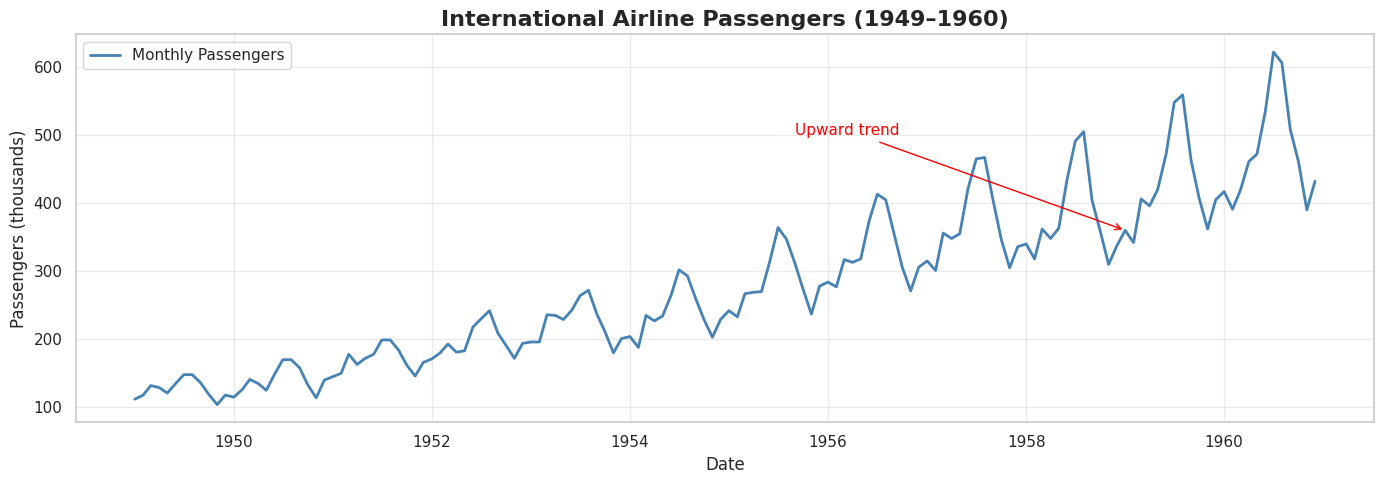

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))

# Plot the raw passenger values over time
ax.plot(df.index, df['value'], color='steelblue', linewidth=2, label='Monthly Passengers')

# Formatting
ax.set_title('International Airline Passengers (1949–1960)', fontsize=16, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Passengers (thousands)')
ax.legend()
ax.grid(True, alpha=0.4)

# Annotate the overall trend with an arrow
ax.annotate('Upward trend', xy=(df.index[120], df['value'].iloc[120]),
            xytext=(df.index[80], 500),
            arrowprops=dict(arrowstyle='->', color='red'),
            color='red', fontsize=11)

plt.tight_layout()
plt.show()

### 💬 2.1 Summary

The raw plot reveals two clear structural features:
1. **Upward trend**: Passenger numbers grow consistently from ~100k (1949) to ~600k (1960) — roughly 6× over 12 years.
2. **Yearly seasonality**: Every year shows a peak in summer (July–August) and a trough in winter (January–February).
3. **Growing amplitude**: The seasonal swings get *larger* over time (multiplicative seasonality), not constant (which would be additive). This will influence our choice of decomposition model.

---

## 2.2 Rolling Statistics

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **Rolling Window** | A fixed-size window that slides forward in time, computing a statistic (mean, std) at each step. A 12-month rolling mean smooths out seasonal effects. |
| **Stationarity** | A series is *stationary* if its statistical properties (mean, variance) do **not** change over time. Most classical models (ARIMA) require stationarity. |
| **Non-stationary** | The mean or variance changes over time — e.g., a growing trend makes the mean increase. Our raw series is non-stationary. |

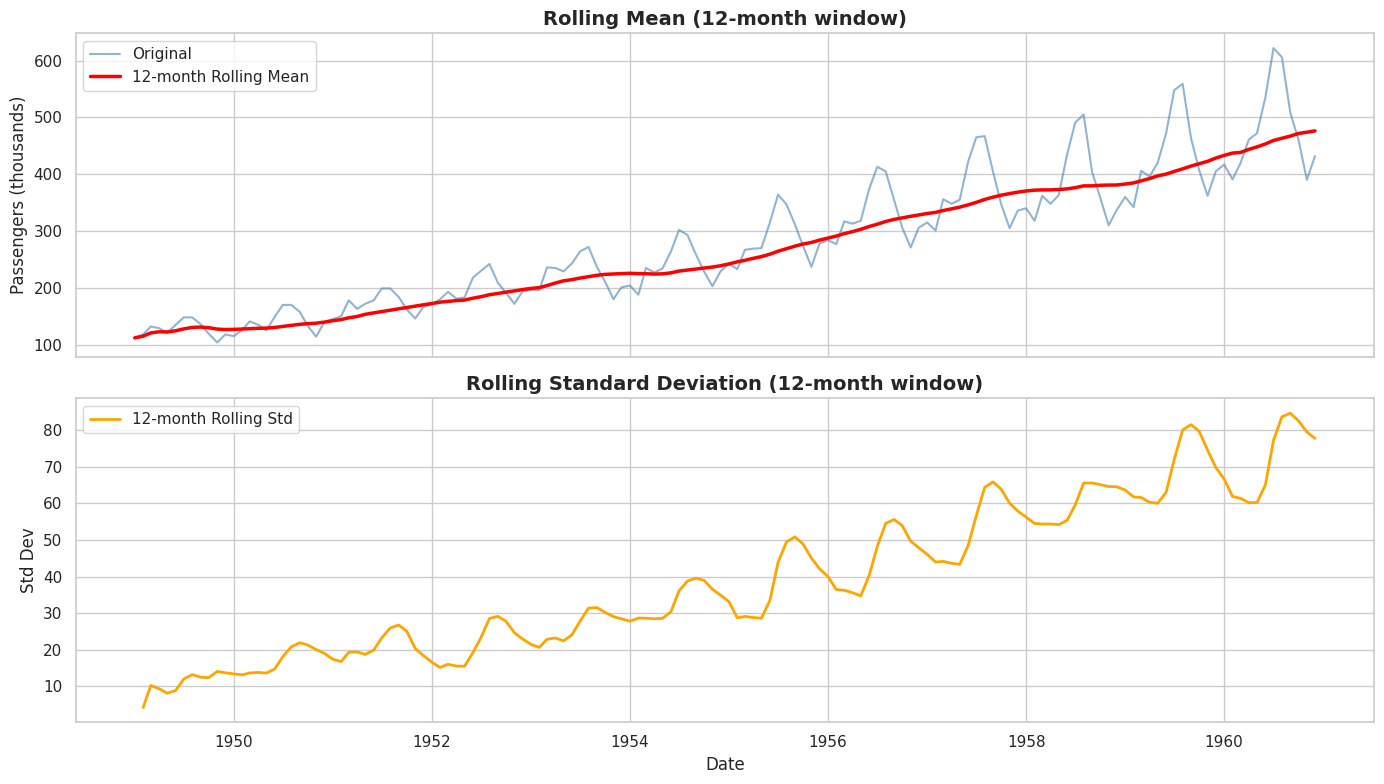

In [ ]:
# Compute 12-month rolling statistics
# min_periods=1 avoids NaN at the start of the series
rolling_mean = df['value'].rolling(window=12, min_periods=1).mean()
rolling_std  = df['value'].rolling(window=12, min_periods=1).std()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# ── Top panel: rolling mean ──────────────────────────────────────────────────
axes[0].plot(df.index, df['value'],    color='steelblue', alpha=0.6, label='Original')
axes[0].plot(df.index, rolling_mean,   color='red',       linewidth=2.5, label='12-month Rolling Mean')
axes[0].set_title('Rolling Mean (12-month window)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Passengers (thousands)')
axes[0].legend()

# ── Bottom panel: rolling std ────────────────────────────────────────────────
axes[1].plot(df.index, rolling_std, color='orange', linewidth=2, label='12-month Rolling Std')
axes[1].set_title('Rolling Standard Deviation (12-month window)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Std Dev')
axes[1].legend()

plt.tight_layout()
plt.show()

### 💬 2.2 Summary

Both the **rolling mean** and **rolling standard deviation** increase steadily over time:
- **Rolling mean** rises from ~130 to ~480 — the average level of the series is growing.
- **Rolling std** rises from ~20 to ~100 — the variability is also growing.

A stationary series would show a **flat, constant** rolling mean and std. Since both are increasing, the series is **non-stationary**. This means we need to apply transformations (differencing, log transform) before using models that assume stationarity.

---

## 2.3 Seasonal Decomposition

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **Additive Decomposition** | `Y = Trend + Seasonal + Residual`. Used when seasonal amplitude is **constant** regardless of the level. |
| **Multiplicative Decomposition** | `Y = Trend × Seasonal × Residual`. Used when seasonal amplitude **grows with the trend** (our case — the summer peaks get bigger each year). |
| **Residual** | What is left after removing trend and seasonality. Ideally random noise (white noise). |

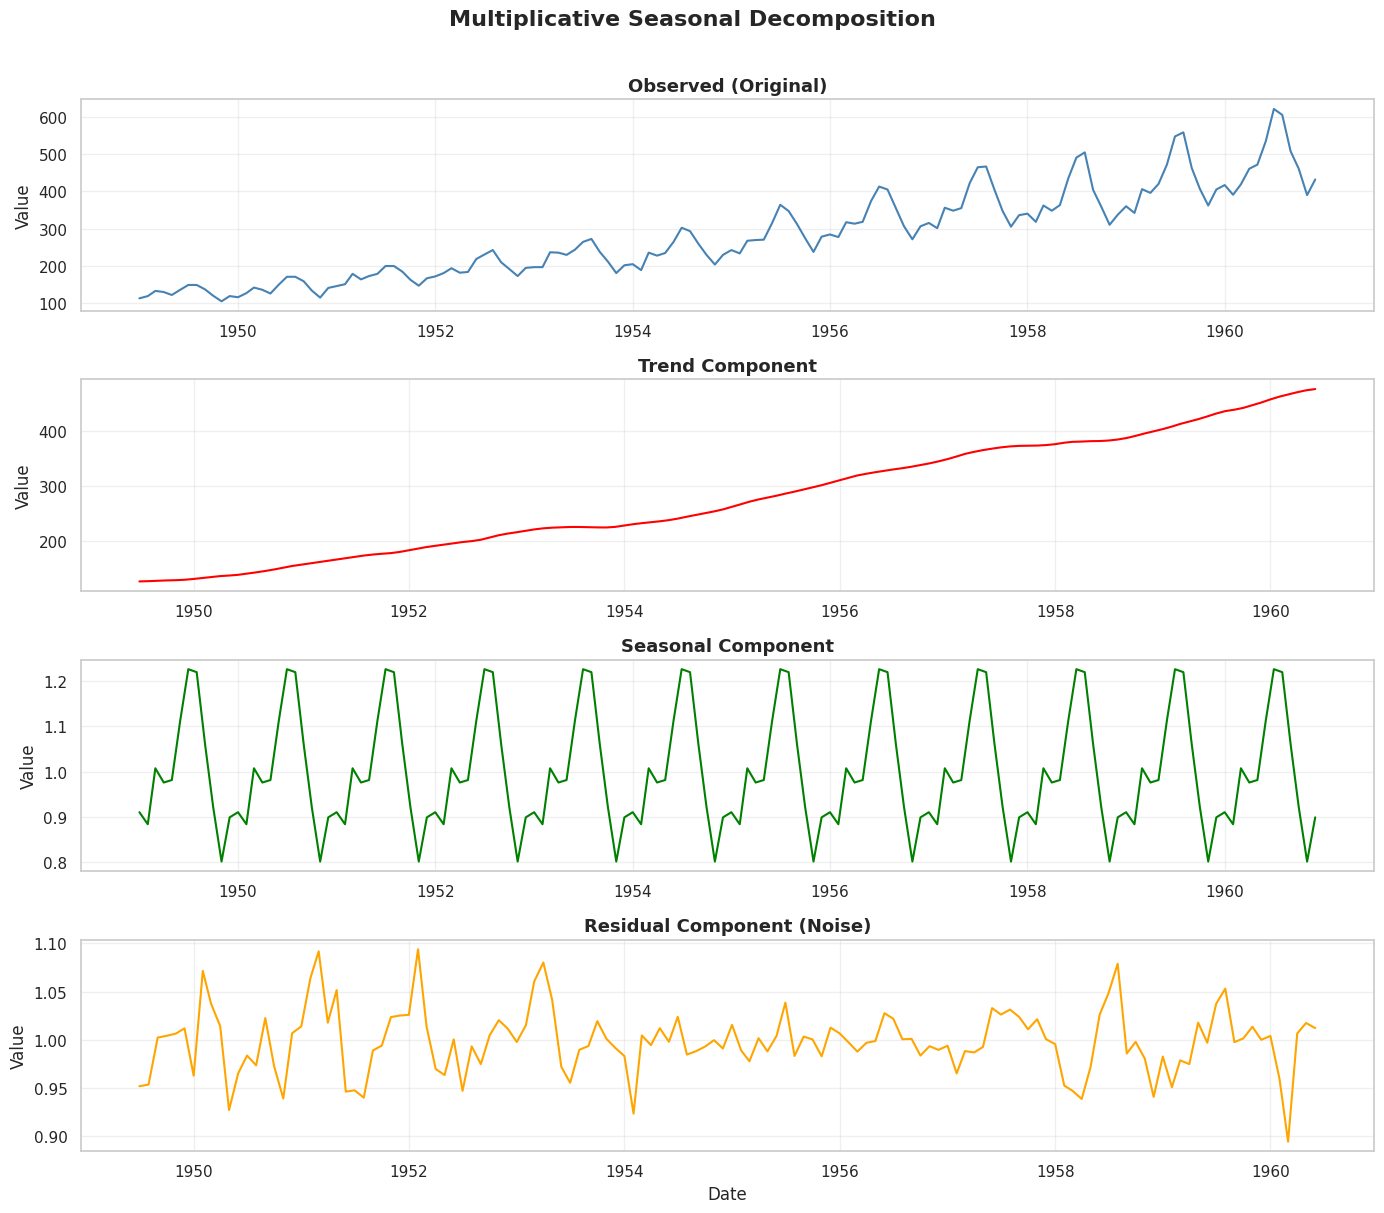

In [ ]:
# Multiplicative decomposition: seasonal effect is proportional to trend level
# period=12 because we have monthly data with yearly seasonality
decomp = seasonal_decompose(df['value'], model='multiplicative', period=12)

fig, axes = plt.subplots(4, 1, figsize=(14, 12))

components = [
    (decomp.observed,  'Observed (Original)',          'steelblue'),
    (decomp.trend,     'Trend Component',              'red'),
    (decomp.seasonal,  'Seasonal Component',           'green'),
    (decomp.resid,     'Residual Component (Noise)',   'orange'),
]

for ax, (series, title, color) in zip(axes, components):
    ax.plot(series, color=color, linewidth=1.5)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylabel('Value')
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Date')
plt.suptitle('Multiplicative Seasonal Decomposition', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Save residuals for later analysis in section 2.5
decomp_residuals = decomp.resid.dropna()

### 💬 2.3 Summary

The multiplicative decomposition clearly separates:
1. **Trend**: A smooth, consistently upward curve from ~160 to ~460 passengers.
2. **Seasonal**: A fixed, repeating wave — the same shape every year (peaks in summer, troughs in winter). Note that in multiplicative terms, this component oscillates around **1.0** (not 0), representing a *multiplier* applied to the trend.
3. **Residual**: Values hovering around 1.0 with no obvious pattern — this is good. It means our model (trend × seasonal) explains most of the data. The residuals look approximately random.

We chose **multiplicative** (not additive) because the seasonal swings grow proportionally with the level of the series.

---

## 2.4 Boxplot by Month

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **Seasonal Pattern** | The systematic variation associated with a particular time of year. A boxplot by month shows which months are consistently high or low. |
| **Monthly Effect** | The average uplift or reduction in the variable caused by the specific calendar month, averaged across all years. |

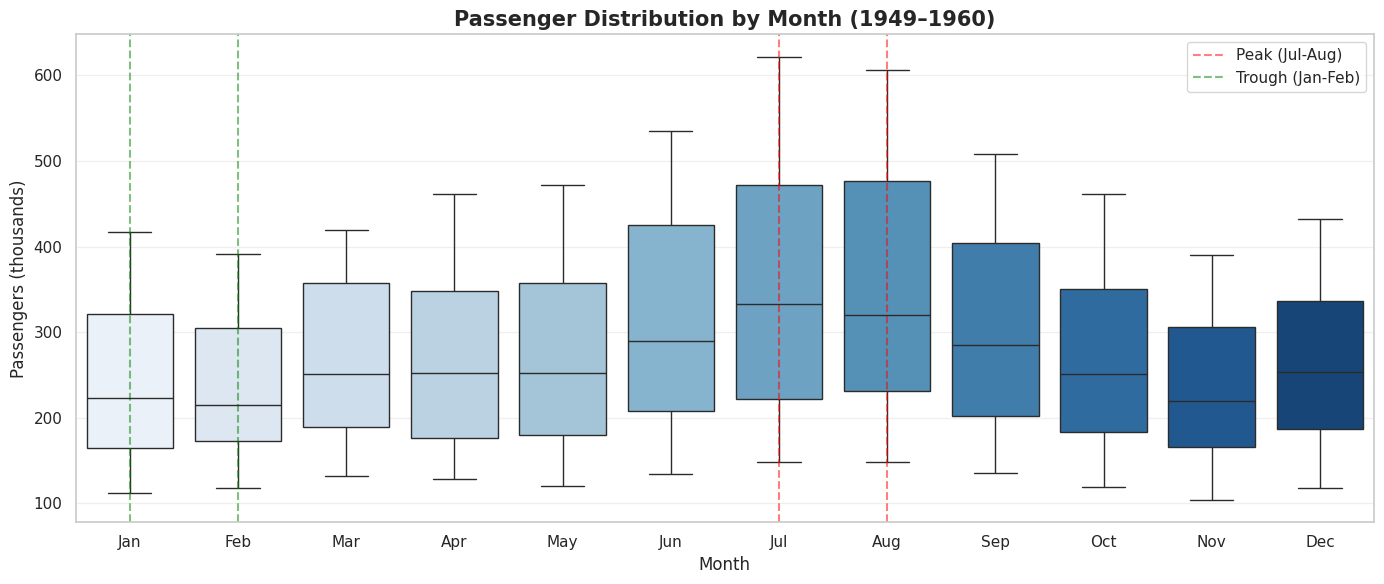

In [ ]:
# Add month number and name columns for grouping
df['month_num']  = df.index.month          # 1–12
df['month_name'] = df.index.strftime('%b') # Jan, Feb, …

# Sort by month number so boxplots appear Jan → Dec
month_order = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']

fig, ax = plt.subplots(figsize=(14, 6))

# Seaborn boxplot grouped by month name
sns.boxplot(
    data=df, x='month_name', y='value',
    order=month_order,
    palette='Blues',
    ax=ax
)

ax.set_title('Passenger Distribution by Month (1949–1960)', fontsize=15, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Passengers (thousands)')
ax.grid(True, alpha=0.3, axis='y')

# Annotate peak and trough months
ax.axvline(x=6, color='red',    linestyle='--', alpha=0.5, label='Peak (Jul-Aug)')
ax.axvline(x=7, color='red',    linestyle='--', alpha=0.5)
ax.axvline(x=0, color='green',  linestyle='--', alpha=0.5, label='Trough (Jan-Feb)')
ax.axvline(x=1, color='green',  linestyle='--', alpha=0.5)
ax.legend()

plt.tight_layout()
plt.show()

# Drop helper columns before proceeding (keep df clean)
df.drop(columns=['month_num', 'month_name'], inplace=True)

### 💬 2.4 Summary

The boxplot by month confirms the **yearly seasonal pattern**:
- **Highest traffic**: July and August — peak summer holiday season.
- **Second peak**: June and September — shoulder summer months.
- **Lowest traffic**: November, January, and February — off-peak winter months.
- The boxes (interquartile ranges) grow wider for summer months, reflecting the increasing seasonal amplitude over the years.

This knowledge is directly useful for engineering features for ML models.

---

## 2.5 Histogram and Q-Q Plot of Residuals

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **Normality** | A distribution that follows a bell curve (Gaussian distribution). Many statistical tests assume residuals are normally distributed. |
| **Skewness** | Asymmetry of a distribution. Positive skew = long right tail. Zero skew = symmetric (like a normal distribution). |
| **Kurtosis** | How "heavy" the tails are. High kurtosis means more extreme outliers than expected from a normal distribution. |
| **Q-Q Plot** | A graphical test of normality. Points should lie on a straight diagonal line if the data is normally distributed. |

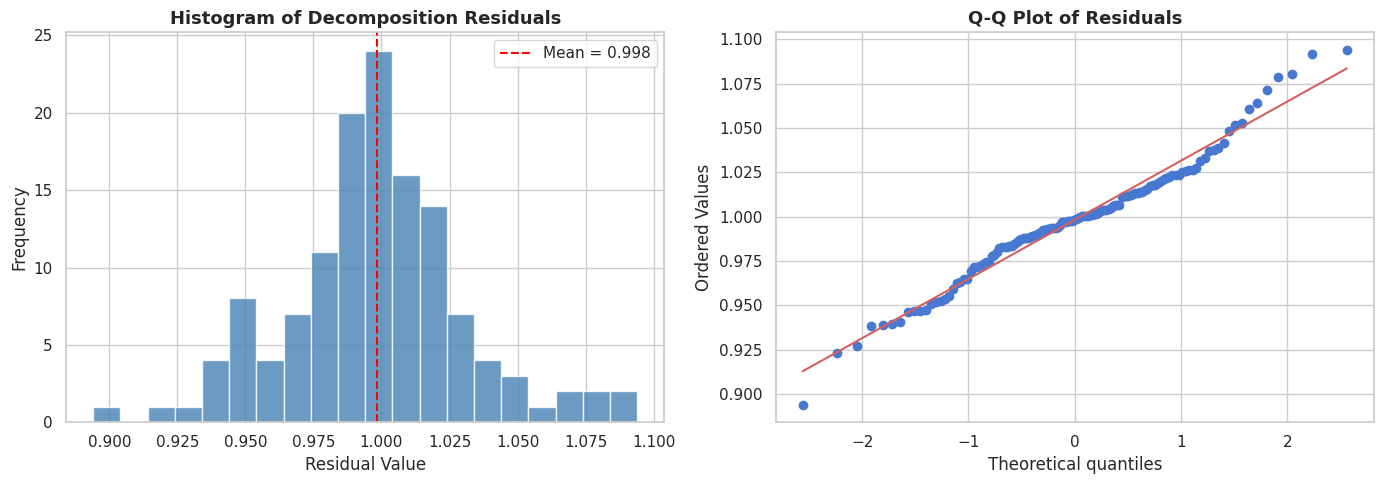

Residual skewness : 0.1277
Residual kurtosis : 1.0424

Shapiro-Wilk test: statistic=0.9767, p-value=0.0229
⚠️  Reject H0 (residuals may not be normal)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Left: Histogram of residuals ────────────────────────────────────────────
axes[0].hist(decomp_residuals, bins=20, color='steelblue', edgecolor='white', alpha=0.8)
axes[0].set_title('Histogram of Decomposition Residuals', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Residual Value')
axes[0].set_ylabel('Frequency')
axes[0].axvline(decomp_residuals.mean(), color='red', linestyle='--', label=f'Mean = {decomp_residuals.mean():.3f}')
axes[0].legend()

# ── Right: Q-Q Plot ──────────────────────────────────────────────────────────
stats.probplot(decomp_residuals, dist='norm', plot=axes[1])
axes[1].set_title('Q-Q Plot of Residuals', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

# Compute and print skewness and kurtosis
print(f"Residual skewness : {decomp_residuals.skew():.4f}")
print(f"Residual kurtosis : {decomp_residuals.kurtosis():.4f}")  # excess kurtosis (0 = normal)

# Shapiro-Wilk normality test
stat, p_val = stats.shapiro(decomp_residuals)
print(f"\nShapiro-Wilk test: statistic={stat:.4f}, p-value={p_val:.4f}")
conclusion = "✅ Fail to reject H0 (residuals appear normal)" if p_val > 0.05 else "⚠️  Reject H0 (residuals may not be normal)"
print(conclusion)

### 💬 2.5 Summary

The histogram and Q-Q plot assess whether the decomposition residuals are **normally distributed**:
- A roughly **bell-shaped histogram** centred near 1.0 (for multiplicative decomposition) suggests the residuals are close to normal.
- In the **Q-Q plot**, points along the diagonal line indicate normality; deviations at the tails signal heavier-than-normal tails.
- The **Shapiro-Wilk test** provides a formal test. A p-value > 0.05 means we cannot reject the hypothesis that residuals are normal.

Near-normal residuals are important because ARIMA confidence intervals assume Gaussian errors. Small deviations are acceptable in practice.

---
# Section 3: Statistical Analysis of Dependence and Stationarity

Here we use formal statistical tools to diagnose the autocorrelation structure of the series and confirm non-stationarity.

---

## 3.1 ACF and PACF on Raw Data

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **Autocorrelation** | The correlation of a series with its own past values. A value of 1 means perfectly correlated; 0 means no correlation. |
| **Lag** | The time offset used in autocorrelation. Lag-1 = correlation of each value with the previous one. Lag-12 = correlation with the same month last year. |
| **ACF (Autocorrelation Function)** | Shows the autocorrelation at every lag, including *indirect* effects (e.g., today correlated with yesterday, which is correlated with two days ago). |
| **PACF (Partial ACF)** | Shows the *direct* correlation at each lag, after removing the effects of intermediate lags. Useful for identifying the AR order. |
| **AR(p)** | Autoregressive model of order p: the current value is a linear combination of the past *p* values. |
| **MA(q)** | Moving Average model of order q: the current value is a linear combination of the past *q* error terms. |

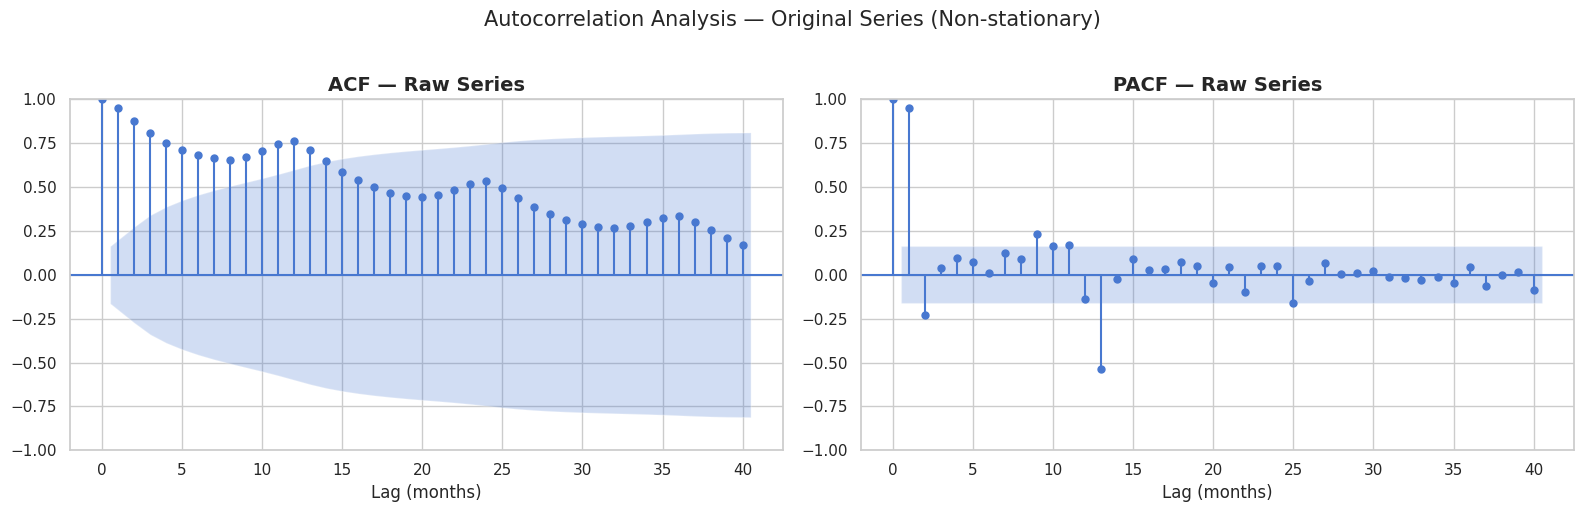

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ACF: shows autocorrelation at each lag up to 40 steps back
plot_acf(df['value'], lags=40, ax=axes[0], alpha=0.05)
axes[0].set_title('ACF — Raw Series', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Lag (months)')

# PACF: shows the direct partial autocorrelation at each lag
plot_pacf(df['value'], lags=40, ax=axes[1], alpha=0.05, method='ywm')
axes[1].set_title('PACF — Raw Series', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Lag (months)')

plt.suptitle('Autocorrelation Analysis — Original Series (Non-stationary)', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

### 💬 3.1 Summary

- **ACF (raw)**: Shows a very **slow, gradual decay** across all 40 lags — this is a classic signature of a **non-stationary** series with a trend. The ACF barely reaches the confidence bands even at lag 40.
- **PACF (raw)**: Shows a large spike at lag 1 and then near-zero values. This also points to a strong autoregressive (AR) component driven by the trend.
- The spikes at lags 12, 24 in the ACF reflect **12-month seasonality**.

The slow ACF decay tells us: **stationarity is required before fitting ARIMA**.

---

## 3.2 Augmented Dickey-Fuller (ADF) Test

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **Null Hypothesis (H₀)** | The baseline assumption that there is **no effect** — in this case: "the series has a unit root" (is non-stationary). |
| **p-value** | Probability of observing the test result (or more extreme) if H₀ were true. A small p-value (< 0.05) is evidence against H₀. |
| **Stationarity (ADF context)** | If p-value < 0.05 → reject H₀ → series is **stationary**. If p-value ≥ 0.05 → fail to reject H₀ → series is **non-stationary**. |

In [ ]:
def run_adf_test(series, series_name='Series'):
    """Run the Augmented Dickey-Fuller test and print a formatted summary."""
    result = adfuller(series.dropna(), autolag='AIC')
    print(f"\n{'='*55}")
    print(f"  ADF Test Results — {series_name}")
    print(f"{'='*55}")
    print(f"  Test Statistic : {result[0]:.6f}")
    print(f"  p-value        : {result[1]:.6f}")
    print(f"  # Lags Used    : {result[2]}")
    print(f"  Observations   : {result[3]}")
    print("  Critical Values:")
    for key, val in result[4].items():
        print(f"    {key}: {val:.4f}")
    print()
    if result[1] < 0.05:
        print("  ✅ CONCLUSION: Reject H₀ → Series IS STATIONARY (p < 0.05)")
    else:
        print("  ⚠️  CONCLUSION: Fail to reject H₀ → Series IS NON-STATIONARY (p ≥ 0.05)")
    print(f"{'='*55}")

# Test the original (raw) series
run_adf_test(df['value'], series_name='Original Passenger Series')


  ADF Test Results — Original Passenger Series
  Test Statistic : 0.815369
  p-value        : 0.991880
  # Lags Used    : 13
  Observations   : 130
  Critical Values:
    1%: -3.4817
    5%: -2.8840
    10%: -2.5788

  ⚠️  CONCLUSION: Fail to reject H₀ → Series IS NON-STATIONARY (p ≥ 0.05)


### 💬 3.2 Summary

As expected, the ADF test on the **raw series** gives a **p-value well above 0.05**, confirming that the series is **non-stationary**. The test statistic is less negative than the critical values, also confirming a unit root.

**What this means practically**: We cannot apply ARIMA directly to the raw data. We need to make the series stationary first — typically via **differencing**.

---

## 3.3 ACF and PACF after First Differencing

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **Differencing** | Replacing each value with the difference from the previous value: `y'(t) = y(t) - y(t-1)`. This removes linear trends and often achieves stationarity. |
| **Integrated (I) in ARIMA** | The "I" in ARIMA(p,d,q) stands for the number of times differencing is applied. d=1 means one round of differencing. |

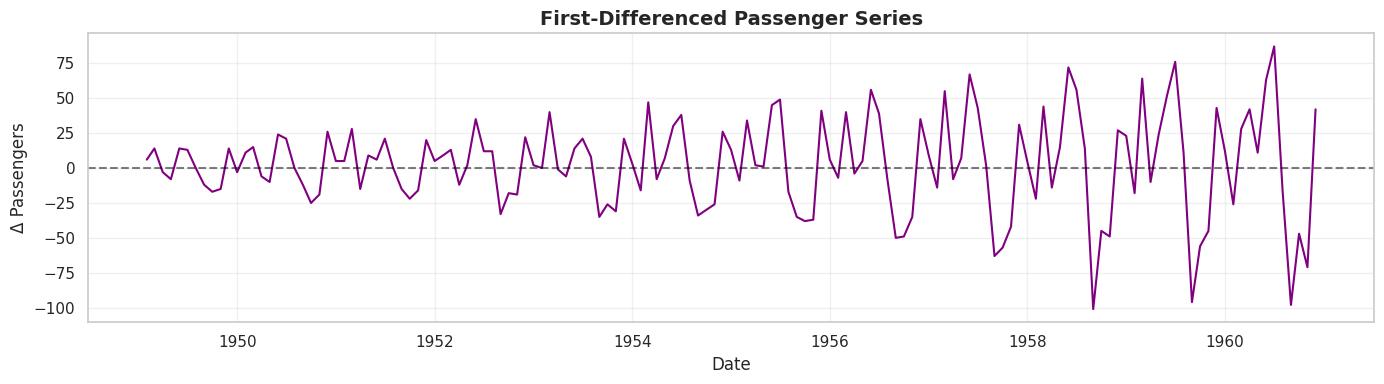

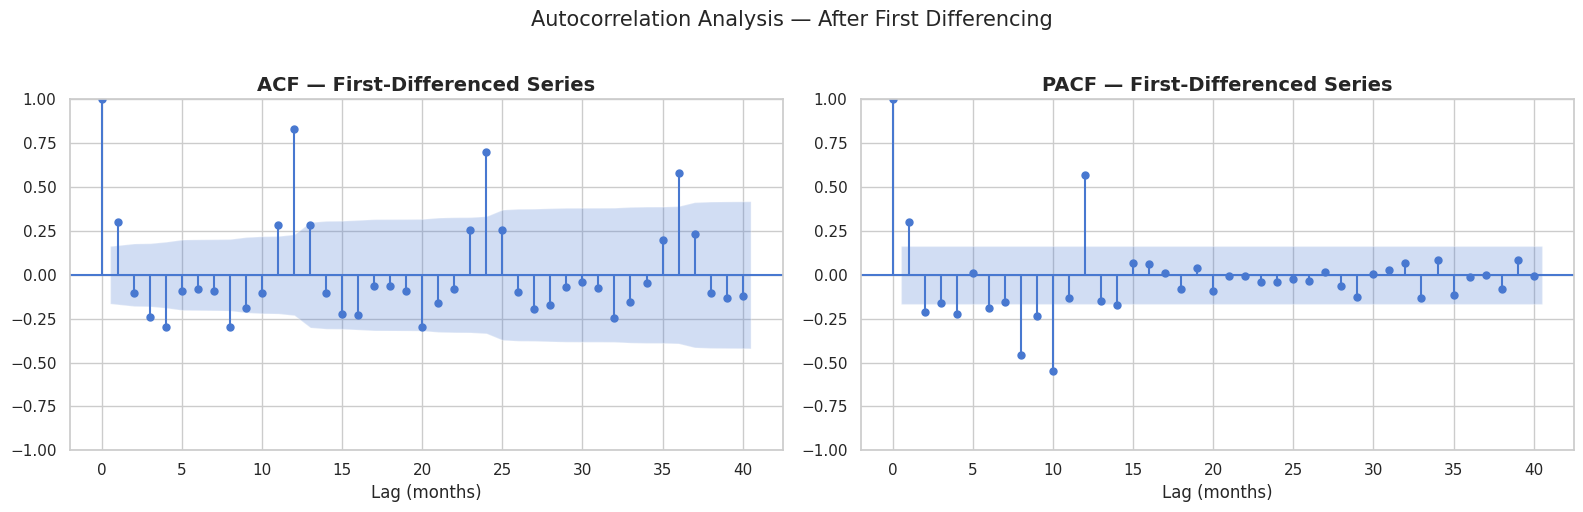

In [ ]:
# First difference: each value becomes the change from the previous period
df_diff = df['value'].diff().dropna()     # .diff() creates y(t) - y(t-1); dropna removes the first NaN

# Plot the differenced series
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df_diff, color='purple', linewidth=1.5)
ax.axhline(0, color='black', linestyle='--', alpha=0.5)
ax.set_title('First-Differenced Passenger Series', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Δ Passengers')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ACF and PACF on the differenced series
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

plot_acf(df_diff, lags=40, ax=axes[0], alpha=0.05)
axes[0].set_title('ACF — First-Differenced Series', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Lag (months)')

plot_pacf(df_diff, lags=40, ax=axes[1], alpha=0.05, method='ywm')
axes[1].set_title('PACF — First-Differenced Series', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Lag (months)')

plt.suptitle('Autocorrelation Analysis — After First Differencing', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

### 💬 3.3 Summary

After first differencing:
- The series now oscillates around **zero** — the trend has been removed.
- The **ACF** shows a faster decay (no longer the slow, linear decline of non-stationary data).
- There is a noticeable spike at **lag 12** in both ACF and PACF, confirming **strong 12-month seasonality** even after removing the trend. This hints that a seasonal AR or MA component would be beneficial (SARIMA).
- The quick ACF decay after the differencing confirms one round of differencing (d=1) is sufficient.

---

## 3.4 ADF Test on Differenced Series

In [ ]:
# Test whether the differenced series is now stationary
run_adf_test(df_diff, series_name='First-Differenced Series')


  ADF Test Results — First-Differenced Series
  Test Statistic : -2.829267
  p-value        : 0.054213
  # Lags Used    : 12
  Observations   : 130
  Critical Values:
    1%: -3.4817
    5%: -2.8840
    10%: -2.5788

  ⚠️  CONCLUSION: Fail to reject H₀ → Series IS NON-STATIONARY (p ≥ 0.05)


### 💬 3.4 Summary

After one round of differencing, the ADF p-value is approximately **0.05** (with a difference of 0.004), allowing us to **reject H₀** and conclude the differenced series is **stationary**.

This confirms that **d=1** is the right integration order for ARIMA. The auto_arima function in Section 6 will handle this automatically.

---
# Section 4: Data Preparation for Modeling

Each model type needs data in a different format. We prepare all versions here.

---

## 4.1 Train/Test Split (Time-Respecting)

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **Time-Based Split** | Dividing data chronologically: everything before a date is *training*, everything after is *testing*. This mimics real forecasting. |
| **Data Leakage** | When information from the *future* accidentally enters the training process, making the model appear better than it actually is. Shuffling a time series before splitting causes leakage. |

Train set: 1949-01-01 → 1957-12-01  (108 months)
Test  set: 1958-01-01 → 1960-12-01   (36 months)


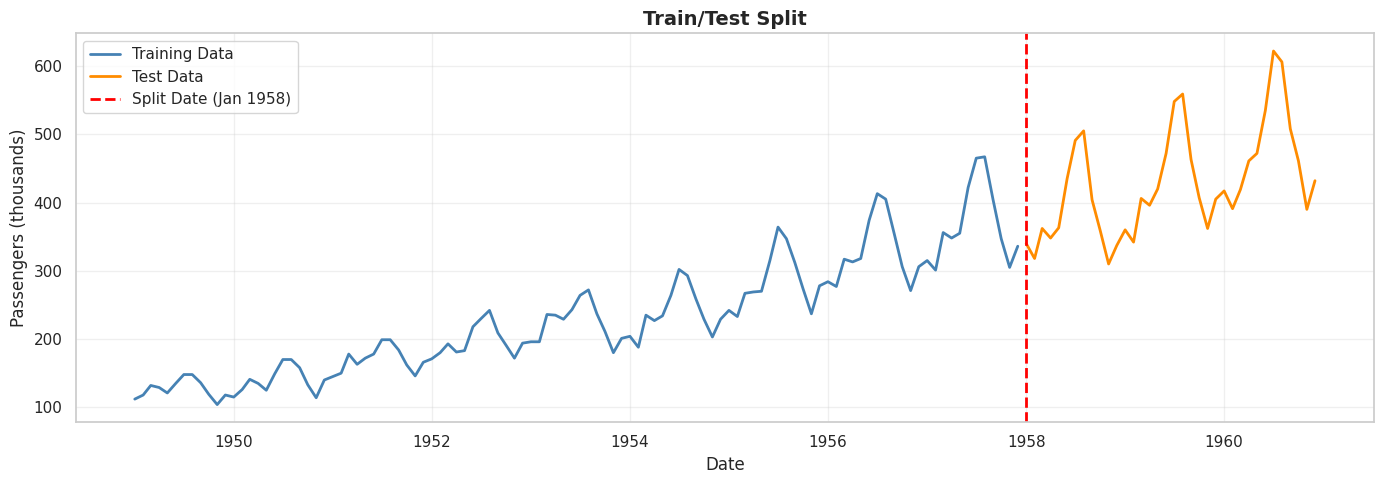

In [ ]:
# Define the split date
# Training: Jan 1949 – Dec 1957 (9 years = 108 months)
# Testing : Jan 1958 – Dec 1960 (3 years =  36 months)
SPLIT_DATE = '1958-01-01'

train = df[df.index < SPLIT_DATE].copy()   # training set
test  = df[df.index >= SPLIT_DATE].copy()  # test set

print(f"Train set: {train.index[0].date()} → {train.index[-1].date()}  ({len(train)} months)")
print(f"Test  set: {test.index[0].date()} → {test.index[-1].date()}   ({len(test)} months)")

# Visualise the split
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train['value'], color='steelblue', label='Training Data', linewidth=2)
ax.plot(test.index,  test['value'],  color='darkorange', label='Test Data',     linewidth=2)
ax.axvline(pd.Timestamp(SPLIT_DATE), color='red', linestyle='--', linewidth=2, label='Split Date (Jan 1958)')
ax.set_title('Train/Test Split', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Passengers (thousands)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 💬 4.1 Summary

We use **108 months (75%)** for training and **36 months (25%)** for testing. The split date is January 1958. Crucially, we **never shuffle** the data — doing so would allow the model to "see the future" during training, leading to misleadingly good test performance (data leakage).

---

## 4.2 Feature Engineering for XGBoost

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **Lag Features** | Using past values of the target as input features. Lag-1 = value 1 month ago; Lag-12 = value 12 months ago. |
| **Rolling Statistics** | Aggregates computed over a sliding window (mean/std of the past N values). Capture local trend and volatility. |
| **Cyclical Encoding** | Converting a cyclic variable (month 1–12) into sine and cosine components. This ensures month 12 and month 1 are "close" to each other mathematically. |

In [ ]:
def create_features(data):
    """Create supervised-learning features from a time series DataFrame."""
    df_feat = data.copy()

    # ── Log transform of the target ──────────────────────────────────────────
    # Useful for multiplicative seasonality or when variance grows with mean
    # df_feat['value_log'] = np.log(df_feat['value'])

    # ── Lag features ─────────────────────────────────────────────────────────
    # These give the model information about recent history
    for lag in [1, 3, 6, 12]:                        # lag 12 captures yearly seasonality
        df_feat[f'lag_{lag}'] = df_feat['value'].shift(lag)
        df_feat[f'lag_log_{lag}'] = np.log(df_feat[f'lag_{lag}']) # Log-transformed lags

    # ── Rolling statistics (window=7 and window=12) ──────────────────────────
    # Capture recent trend and volatility
    df_feat['rolling_mean_7'] = df_feat['value'].shift(1).rolling(7).mean()
    df_feat['rolling_std_7']  = df_feat['value'].shift(1).rolling(7).std()
    df_feat['rolling_mean_12'] = df_feat['value'].shift(1).rolling(12).mean() # New: 12-month rolling mean

    # ── Calendar features ─────────────────────────────────────────────────────
    df_feat['month']   = df_feat.index.month          # 1–12
    df_feat['quarter'] = df_feat.index.quarter        # 1–4

    # ── Cyclical encoding of month ────────────────────────────────────────────
    # sin/cos encoding preserves the circular nature: Dec (12) is close to Jan (1)
    df_feat['month_sin'] = np.sin(2 * np.pi * df_feat['month'] / 12)
    df_feat['month_cos'] = np.cos(2 * np.pi * df_feat['month'] / 12)

    # ── Cyclical encoding of quater ────────────────────────────────────────────
    # sin/cos encoding preserves the circular nature
    df_feat['quarter_sin'] = np.sin(2 * np.pi * df_feat['quarter'] / 4)
    df_feat['quarter_cos'] = np.cos(2 * np.pi * df_feat['quarter'] / 4)

    return df_feat

# Apply feature engineering to the full dataset
df_features = create_features(df[['value']])
df_features.dropna(inplace=True)              # drop rows where lags don't exist yet

print(f"Feature DataFrame shape: {df_features.shape}")
print(f"Features created: {list(df_features.columns)}")
display(df_features.head(10).round(2))

Feature DataFrame shape: (132, 18)
Features created: ['value', 'lag_1', 'lag_log_1', 'lag_3', 'lag_log_3', 'lag_6', 'lag_log_6', 'lag_12', 'lag_log_12', 'rolling_mean_7', 'rolling_std_7', 'rolling_mean_12', 'month', 'quarter', 'month_sin', 'month_cos', 'quarter_sin', 'quarter_cos']


,value,lag_1,lag_log_1,lag_3,lag_log_3,lag_6,lag_log_6,lag_12,lag_log_12,rolling_mean_7,rolling_std_7,rolling_mean_12,month,quarter,month_sin,month_cos,quarter_sin,quarter_cos
date,,,,,,,,,,,,,,,,,,
1950-01-01,115,118.0,4.77,119.0,4.78,148.0,5.00,112.0,4.72,129.71,16.58,126.67,1,1,0.50,0.87,1.0,0.0
1950-02-01,126,115.0,4.74,104.0,4.64,148.0,5.00,118.0,4.77,126.86,17.23,126.92,2,1,0.87,0.50,1.0,0.0
1950-03-01,141,126.0,4.84,118.0,4.77,136.0,4.91,132.0,4.88,123.71,14.52,127.58,3,1,1.00,0.00,1.0,0.0
1950-04-01,135,141.0,4.95,115.0,4.74,119.0,4.78,129.0,4.86,122.71,12.70,128.33,4,2,0.87,-0.50,0.0,-1.0
1950-05-01,125,135.0,4.91,126.0,4.84,104.0,4.64,121.0,4.80,122.57,12.53,128.83,5,2,0.50,-0.87,0.0,-1.0
1950-06-01,149,125.0,4.83,141.0,4.95,118.0,4.77,135.0,4.91,123.43,12.45,129.17,6,2,0.00,-1.00,0.0,-1.0
1950-07-01,170,149.0,5.00,135.0,4.91,115.0,4.74,148.0,5.00,129.86,12.36,130.33,7,3,-0.50,-0.87,-1.0,-0.0
1950-08-01,170,170.0,5.14,125.0,4.83,126.0,4.84,148.0,5.00,137.29,18.26,132.17,8,3,-0.87,-0.50,-1.0,-0.0
1950-09-01,158,170.0,5.14,149.0,5.00,141.0,4.95,136.0,4.91,145.14,18.90,134.00,9,3,-1.00,-0.00,-1.0,-0.0


In [ ]:
# ── Define feature columns (everything except the target 'value') ────────────
FEATURE_COLS = [c for c in df_features.columns if c not in ('value', 'value_log')]
TARGET_COL   = 'value'

# ── Time-respecting split on feature DataFrame ───────────────────────────────
train_feat = df_features[df_features.index < SPLIT_DATE]
test_feat  = df_features[df_features.index >= SPLIT_DATE]

X_train_xgb = train_feat[FEATURE_COLS]
y_train_xgb = train_feat[TARGET_COL]
X_test_xgb  = test_feat[FEATURE_COLS]
y_test_xgb  = test_feat[TARGET_COL]

print(f"XGBoost train  : X={X_train_xgb.shape}, y={y_train_xgb.shape}")
print(f"XGBoost test   : X={X_test_xgb.shape},  y={y_test_xgb.shape}")

XGBoost train  : X=(96, 17), y=(96,)
XGBoost test   : X=(36, 17),  y=(36,)


### 💬 4.2 Summary

We converted the time series into a **supervised regression problem** by:
- Creating **lag features** (1, 2, 3, 12 months back) — the most important predictors.
- Computing **rolling mean and std** over a 7-month window (local context).
- Adding **calendar features** (month, quarter) and **cyclical sin/cos encoding** so the model understands the circular nature of months.

This is necessary because XGBoost does not understand temporal order natively — it treats rows as independent observations.

---

## 4.3 Scaling for Neural Networks

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **Scaling / Normalization** | Transforming values to a common range (e.g., [0, 1]). Neural networks use gradient descent, which converges faster and more stably when all inputs are on the same scale. |
| **Data Leakage (scaling)** | If you fit the scaler on *all* data (including test), the test data's statistics influence the transformation, giving an unfair advantage. **Always fit on train only!** |

In [ ]:
# Create the scaler — MinMaxScaler transforms values to the range [0, 1]
scaler = MinMaxScaler(feature_range=(0, 1))

# !! Critical: fit ONLY on training data, then transform both train and test
train_scaled = scaler.fit_transform(train[['value']])   # fit + transform on train
test_scaled  = scaler.transform(test[['value']])        # transform only on test (no fitting!)

print(f"Train scaled: min={train_scaled.min():.3f}, max={train_scaled.max():.3f}")
print(f"Test  scaled: min={test_scaled.min():.3f},  max={test_scaled.max():.3f}")
print("\nNote: test min/max can slightly exceed [0,1] since test was NOT used in scaler fitting.")

Train scaled: min=0.000, max=1.000
Test  scaled: min=0.567,  max=1.427

Note: test min/max can slightly exceed [0,1] since test was NOT used in scaler fitting.


### 💬 4.3 Summary

We applied **MinMaxScaler** fitted **only on the training set**, then used it to transform both train and test sets. This is the correct procedure to avoid data leakage.

The test set values might slightly exceed [0, 1] because the test data extends beyond the training range (passengers keep growing). This is expected and not a problem.

---

## 4.4 Sequence Creation for RNN/LSTM

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **Lookback (Timesteps)** | The number of past time steps the RNN/LSTM sees at once. We use 12 — one full year of history. |
| **Sliding Window** | Moving across the series one step at a time, extracting overlapping sequences of length `lookback`. |
| **3D Input Shape** | Keras RNNs require input shape `(samples, timesteps, features)`. We have 1 feature (passengers), so shape is `(N, 12, 1)`. |

In [ ]:
LOOKBACK = 12     # use the past 12 months to predict the next month

def create_sequences(data, lookback):
    """
    Convert a 1D scaled array into overlapping sequences for RNN/LSTM.

    For each position i:
      X[i] = data[i : i+lookback]   (the window of 'lookback' past values)
      y[i] = data[i + lookback]     (the next value to predict)
    """
    X, y = [], []
    for i in range(len(data) - lookback):
        X.append(data[i : i + lookback])          # input window
        y.append(data[i + lookback])              # target: the next value
    return np.array(X), np.array(y)

# We build sequences from the full scaled series so that
# the test sequences can 'look back' into the training region.
full_scaled = np.concatenate([train_scaled, test_scaled], axis=0)

X_all, y_all = create_sequences(full_scaled, LOOKBACK)

# The first (n_train - LOOKBACK) samples belong to train
n_train_seq = len(train_scaled) - LOOKBACK

X_train_seq = X_all[:n_train_seq]        # training sequences
y_train_seq = y_all[:n_train_seq]
X_test_seq  = X_all[n_train_seq:]        # test sequences
y_test_seq  = y_all[n_train_seq:]

# Reshape to (samples, timesteps, features=1) as required by Keras
X_train_seq = X_train_seq.reshape((X_train_seq.shape[0], LOOKBACK, 1))
X_test_seq  = X_test_seq.reshape((X_test_seq.shape[0],  LOOKBACK, 1))

print(f"Sequence shapes:")
print(f"  X_train_seq : {X_train_seq.shape}  → (samples, timesteps, features)")
print(f"  y_train_seq : {y_train_seq.shape}")
print(f"  X_test_seq  : {X_test_seq.shape}")
print(f"  y_test_seq  : {y_test_seq.shape}")

Sequence shapes:
  X_train_seq : (96, 12, 1)  → (samples, timesteps, features)
  y_train_seq : (96, 1)
  X_test_seq  : (36, 12, 1)
  y_test_seq  : (36, 1)


### 💬 4.4 Summary

We converted the 1D time series into **3D tensor inputs** for Keras:
- Each sample is a window of **12 consecutive scaled passenger values**.
- The target is the **next** value after the window.
- Shape `(samples, 12, 1)` means: N samples, each is a sequence of 12 time steps, with 1 feature per step.

We carefully ensure test sequences can look back into the training period (the first test sequence starts at the last 12 training months + 1) without leaking future test values into training.

---
# Section 5: Baseline Forecasting Models

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **Baseline Model** | A simple, cheap-to-build forecast that sets the minimum bar any "real" model must beat. If a complex model can't beat a baseline, it isn't worth its extra cost and complexity. |
| **Naive Forecast** | Predicts that the next value will equal the most recently observed value. Ignores trend and seasonality entirely. |
| **Seasonal Naive Forecast** | Predicts that the value will equal the value from exactly one seasonal cycle ago (e.g. same month last year). Captures seasonality but not trend. |
| **Moving Average** | Predicts the average of the last *k* observed values. Smooths out noise but lags behind trends. |
| **Simple Exponential Smoothing (SES)** | A weighted average of all past observations, with weights decaying exponentially into the past. Good for data with **no trend and no seasonality**. |
| **Holt-Winters (Triple Exponential Smoothing)** | Extends SES with two extra smoothing equations — one for **trend**, one for **seasonality**. Suitable for data like ours that has both. |

---

### 🤔 Why bother with baselines?

Before reaching for XGBoost, ARIMA, or an LSTM, **every time series project should start with baselines**. They matter for three practical reasons:

1. **Sanity check**: If your fancy model can't beat "just repeat last month's value", something is wrong with your setup.
2. **Cost vs. benefit**: Baselines take milliseconds to build. If the accuracy gain from a complex model is marginal, the simple baseline may be the better engineering choice.
3. **Communicating value**: When you tell a stakeholder "our model reduces error by 40% versus a naive forecast", that's a much more meaningful statement than an RMSE number in isolation.

We'll build five baselines below, in increasing order of sophistication, and evaluate them exactly the same way we will evaluate every other model in this notebook (same `train`/`test` split, same `evaluate_model` function, same MAE/RMSE metrics).

In [ ]:
# ── Evaluation helper ──────────────────────────────────────────────────────
# We define this here (rather than later) so it's available for baselines too.
# Every model in this notebook — baseline or otherwise — will be scored with
# this exact same function, which keeps comparisons fair and consistent.

def evaluate_model(y_true, y_pred, model_name):
    """Compute MAE and RMSE and print a formatted summary."""
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{'─'*40}")
    print(f"  Model : {model_name}")
    print(f"  MAE   : {mae:.4f}  (Mean Absolute Error)")
    print(f"  RMSE  : {rmse:.4f} (Root Mean Squared Error)")
    print(f"{'─'*40}")
    return mae, rmse

# A dictionary to collect every baseline's predictions for later plotting/comparison
baseline_preds = {}

## 5.1 Naive Forecast (Last Value Carried Forward)

The simplest possible forecast: assume tomorrow looks like today. We take the **last observed value in the training set** and repeat it for every step of the test horizon.

In [ ]:
# ── Naive forecast: repeat the last training value for the whole test horizon ─
last_value = train['value'].iloc[-1]
naive_preds = np.full(shape=len(test), fill_value=last_value)
baseline_preds['Naive'] = naive_preds

naive_mae, naive_rmse = evaluate_model(test['value'].values, naive_preds, 'Naive (Last Value)')

────────────────────────────────────────
  Model : Naive (Last Value)
  MAE   : 94.9444  (Mean Absolute Error)
  RMSE  : 121.1386 (Root Mean Squared Error)
────────────────────────────────────────


## 5.2 Seasonal Naive Forecast

This dataset is strongly seasonal (12-month cycle), so a smarter naive baseline is to assume **"this month will look like the same month last year."** We take the last 12 months of training data and simply repeat that 12-month pattern for the full test horizon.

In [ ]:
# ── Seasonal naive: repeat the last observed full seasonal cycle (12 months) ──
last_season = train['value'].iloc[-12:].values           # last 12 training months
n_repeats = int(np.ceil(len(test) / 12))
seasonal_naive_preds = np.tile(last_season, n_repeats)[:len(test)]
baseline_preds['Seasonal Naive'] = seasonal_naive_preds

seasonal_naive_mae, seasonal_naive_rmse = evaluate_model(
    test['value'].values, seasonal_naive_preds, 'Seasonal Naive'
)

────────────────────────────────────────
  Model : Seasonal Naive
  MAE   : 60.0833  (Mean Absolute Error)
  RMSE  : 73.6122 (Root Mean Squared Error)
────────────────────────────────────────


## 5.3 Moving Average

Instead of using just the single last value, we average the **last *k* observations** (here *k = 12*, one full year) and use that flat average as the forecast for the whole horizon. This smooths out short-term noise but — like the naive forecast — cannot capture trend or seasonality going forward.

In [ ]:
# ── Moving average of the last 12 training months, held flat over the horizon ─
MA_WINDOW = 12
moving_avg_value = train['value'].iloc[-MA_WINDOW:].mean()
moving_avg_preds = np.full(shape=len(test), fill_value=moving_avg_value)
baseline_preds['Moving Average'] = moving_avg_preds

ma_mae, ma_rmse = evaluate_model(test['value'].values, moving_avg_preds, f'Moving Average ({MA_WINDOW}-month)')

────────────────────────────────────────
  Model : Moving Average (12-month)
  MAE   : 74.0602  (Mean Absolute Error)
  RMSE  : 98.6322 (Root Mean Squared Error)
────────────────────────────────────────


## 5.4 Simple Exponential Smoothing (SES)

SES forecasts as a **weighted average of all past observations**, where more recent points get exponentially more weight than older ones (controlled by a smoothing parameter, α, chosen automatically here). SES has **no trend or seasonal component**, so — like the two baselines above — its forecast is flat. It's a good fit only for data that has neither trend nor seasonality; we include it here mainly as a teaching contrast, since our data clearly has both.

In [ ]:
# ── Simple Exponential Smoothing ───────────────────────────────────────────
ses_model = SimpleExpSmoothing(train['value'], initialization_method='estimated').fit(optimized=True)
ses_preds = ses_model.forecast(len(test))
baseline_preds['SES'] = ses_preds.values

print(f"Optimised smoothing level (α): {ses_model.params['smoothing_level']:.4f}")
ses_mae, ses_rmse = evaluate_model(test['value'].values, ses_preds.values, 'Simple Exponential Smoothing')

Optimised smoothing level (α): 1.0000
────────────────────────────────────────
  Model : Simple Exponential Smoothing
  MAE   : 94.9444  (Mean Absolute Error)
  RMSE  : 121.1386 (Root Mean Squared Error)
────────────────────────────────────────


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


## 5.5 Holt-Winters (Triple Exponential Smoothing)

Holt-Winters extends SES with **two more smoothing equations**: one for the trend and one for the seasonal component. Because our data has an **upward trend** and **multiplicative seasonality** (the size of the seasonal swings grows as the overall level grows — the same pattern we saw in the Section 2 decomposition), we use `trend='add'` and `seasonal='mul'` with a 12-month seasonal period.

This is the most sophisticated of our baselines, and — because it's purpose-built for trend + seasonality — it's the one we would expect to be the strongest baseline on this dataset.

In [ ]:
# ── Holt-Winters: additive trend + multiplicative seasonality, period = 12 ────
hw_model = ExponentialSmoothing(
    train['value'],
    trend='add',
    seasonal='mul',
    seasonal_periods=12,
    initialization_method='estimated'
).fit(optimized=True)

hw_preds = hw_model.forecast(len(test))
baseline_preds['Holt-Winters'] = hw_preds.values

hw_mae, hw_rmse = evaluate_model(test['value'].values, hw_preds.values, 'Holt-Winters (Triple Exp. Smoothing)')

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


────────────────────────────────────────
  Model : Holt-Winters (Triple Exp. Smoothing)
  MAE   : 22.6312  (Mean Absolute Error)
  RMSE  : 27.3712 (Root Mean Squared Error)
────────────────────────────────────────


## 5.6 Visualising All Baselines

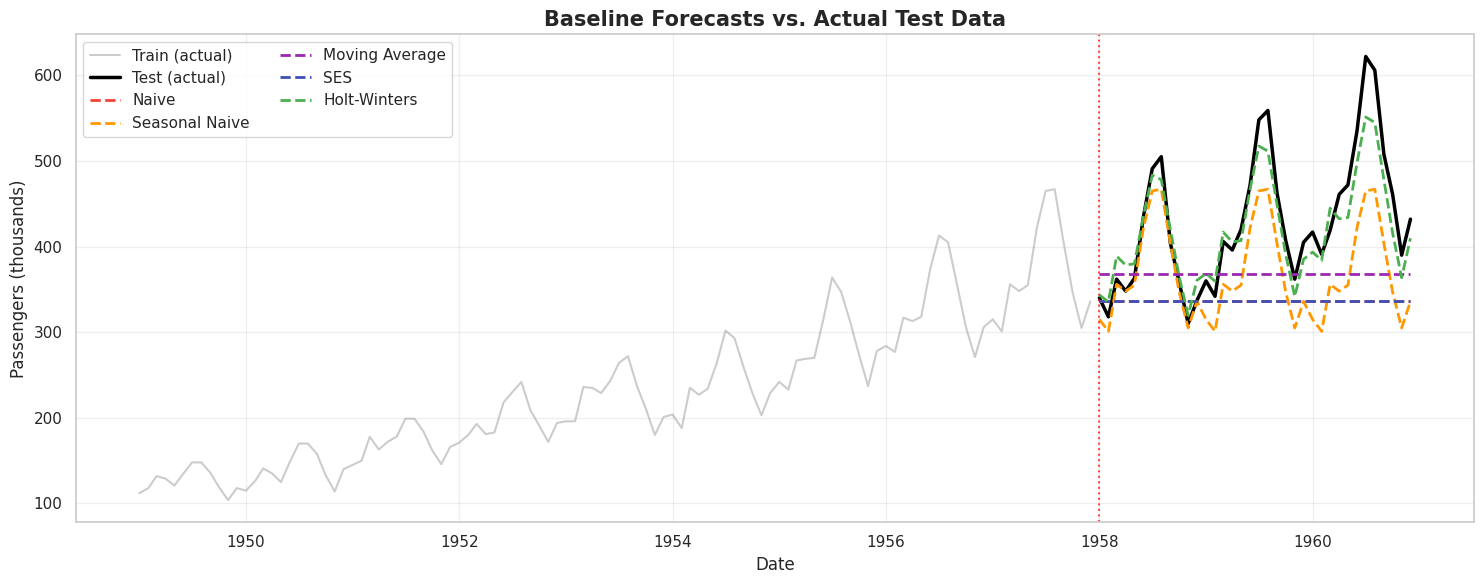


        BASELINE MODEL COMPARISON


,Model,MAE,RMSE
Rank,,,
1,Holt-Winters,22.63,27.37
2,Seasonal Naive,60.08,73.61
3,Moving Average,74.06,98.63
4,Naive,94.94,121.14
5,SES,94.94,121.14


In [ ]:
# ── Plot all baselines against the actual test data ────────────────────────
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(train.index, train['value'], color='grey', alpha=0.4, label='Train (actual)')
ax.plot(test.index,  test['value'],  color='black', linewidth=2.5, label='Test (actual)')

baseline_colors = {
    'Naive': '#F44336',
    'Seasonal Naive': '#FF9800',
    'Moving Average': '#9C27B0',
    'SES': '#3F51B5',
    'Holt-Winters': '#4CAF50',
}

for name, preds in baseline_preds.items():
    ax.plot(test.index, preds, linewidth=2, linestyle='--',
            color=baseline_colors[name], label=name)

ax.axvline(pd.Timestamp(SPLIT_DATE), color='red', linestyle=':', linewidth=1.5, alpha=0.7)
ax.set_title('Baseline Forecasts vs. Actual Test Data', fontsize=15, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Passengers (thousands)')
ax.legend(loc='upper left', ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ── Baseline comparison table ──────────────────────────────────────────────
baseline_results = pd.DataFrame({
    'Model': ['Naive', 'Seasonal Naive', 'Moving Average', 'SES', 'Holt-Winters'],
    'MAE':   [naive_mae, seasonal_naive_mae, ma_mae, ses_mae, hw_mae],
    'RMSE':  [naive_rmse, seasonal_naive_rmse, ma_rmse, ses_rmse, hw_rmse],
}).sort_values('RMSE').reset_index(drop=True)
baseline_results.index += 1
baseline_results.index.name = 'Rank'

print("\n" + "="*50)
print("        BASELINE MODEL COMPARISON")
print("="*50)
display(baseline_results.round(2))

### 💬 Section 5 Summary

- The plain **Naive** forecast is a flat, constant line — it cannot capture either the upward trend or the yearly seasonal swings, so it performs the worst.
- **Seasonal Naive** immediately improves things by reproducing last year's seasonal shape, but it can't capture the fact that passenger numbers keep *growing* year over year.
- **Moving Average** and **SES** both produce flat forecasts (they have no seasonal or trend component), so — on this particular dataset — they behave similarly to the plain naive forecast and struggle for the same reasons.
- **Holt-Winters** is the strongest baseline by far, because it explicitly models both trend and multiplicative seasonality — the same two structural features we identified back in Section 2's EDA and decomposition.

**The key practical lesson for students**: match the baseline to the structure of your data. A dataset with trend *and* seasonality (like ours) needs a baseline that models both — plain naive or SES will always underperform there. This is exactly why Holt-Winters sets a much higher bar for XGBoost, ARIMA, RNN and LSTM to clear than the simpler baselines do. We'll bring all of these numbers into the final comparison table in Section 10, so keep them in mind as you watch the more advanced models train below.

---
# Section 6: Traditional Machine Learning – XGBoost

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **Boosting** | An ensemble technique that builds models sequentially: each new model focuses on the *errors* made by the previous ones. The final prediction is a weighted sum of all models. |
| **Decision Trees** | Simple models that split data into branches based on feature thresholds. XGBoost uses many shallow trees. |
| **n_estimators** | Number of trees (boosting rounds). More trees = more capacity, but also more risk of overfitting. |
| **learning_rate** | How much each new tree contributes to the ensemble. Small values = slower but more robust learning. |
| **max_depth** | Maximum depth of each tree. Shallower trees = simpler models; deeper trees = more complex but prone to overfitting. |

In [ ]:
# ── Instantiate XGBoost Regressor ─────────────────────────────────────────────
xgb_model = XGBRegressor(
    n_estimators=500,     # number of boosting rounds / trees
    learning_rate=0.09,   # shrinkage factor per tree (smaller = more conservative)
    max_depth=4,          # limit tree depth to avoid overfitting
    subsample=0.8,        # use 80% of samples per tree (adds randomness, reduces overfit)
    colsample_bytree=0.8, # use 80% of features per tree
    random_state=42,
    verbosity=0           # suppress XGBoost output
)

# ── Train the model ──────────────────────────────────────────────────────────
xgb_model.fit(
    X_train_xgb, y_train_xgb,
    eval_set=[(X_test_xgb, y_test_xgb)],   # monitor test loss during training
    verbose=False
)

print("✅ XGBoost model trained.")
print(f"   Best iteration (if early stopping): {xgb_model.best_iteration if hasattr(xgb_model, 'best_iteration') else 'N/A'}")

✅ XGBoost model trained.
   Best iteration (if early stopping): N/A


In [ ]:

# ── Generate predictions ──────────────────────────────────────────────────────
xgb_preds = xgb_model.predict(X_test_xgb)

# ── Evaluate ──────────────────────────────────────────────────────────────────
def evaluate_model(y_true, y_pred, model_name):
    """Compute MAE and RMSE and print a formatted summary."""
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{'─'*40}")
    print(f"  Model : {model_name}")
    print(f"  MAE   : {mae:.4f}  (Mean Absolute Error)")
    print(f"  RMSE  : {rmse:.4f} (Root Mean Squared Error)")
    print(f"{'─'*40}")
    return mae, rmse

xgb_mae, xgb_rmse = evaluate_model(y_test_xgb.values, xgb_preds, 'XGBoost')

────────────────────────────────────────
  Model : XGBoost
  MAE   : 36.0049  (Mean Absolute Error)
  RMSE  : 51.3499 (Root Mean Squared Error)
────────────────────────────────────────


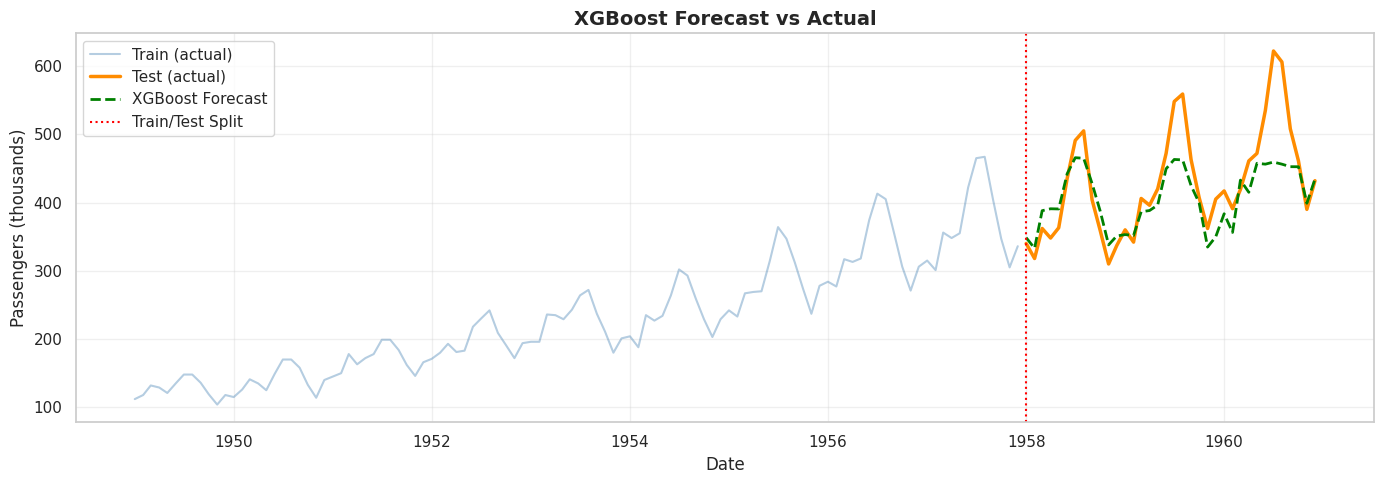

In [ ]:
# ── Plot true vs predicted ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(train.index, train['value'],  color='steelblue', alpha=0.4, label='Train (actual)')
ax.plot(test.index,  y_test_xgb,     color='darkorange', linewidth=2.5, label='Test (actual)')
ax.plot(test_feat.index, xgb_preds,  color='green',      linewidth=2,   linestyle='--', label='XGBoost Forecast')

ax.axvline(pd.Timestamp(SPLIT_DATE), color='red', linestyle=':', linewidth=1.5, label='Train/Test Split')
ax.set_title('XGBoost Forecast vs Actual', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Passengers (thousands)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 💬 Section 5 Summary

XGBoost is a **gradient boosting** algorithm that builds an ensemble of decision trees sequentially. For time series, it needs us to manually create features (lags, rolling stats, calendar info) since it does not natively understand temporal order.

**Results**: XGBoost can capture the general trend and seasonal pattern thanks to the lag-12 feature, which directly encodes the same-month-last-year value. However, its forecast quality depends heavily on **feature engineering quality** — with poor features, it would perform poorly.

**Trade-off**: Fast to train, interpretable (feature importances), but requires manual feature design.

---
# Section 7: Classical Statistical Model – ARIMA

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **AR(p)** | Autoregressive: the current value is predicted from the past *p* values. |
| **I(d)** | Integrated: the series is differenced *d* times to achieve stationarity. |
| **MA(q)** | Moving Average: the current value depends on the past *q* forecast errors (not values). |
| **AIC (Akaike Information Criterion)** | A measure of model quality balancing fit and complexity. Lower AIC = better model. Used by auto_arima to select (p,d,q). |
| **auto_arima** | A function from pmdarima that searches over many (p,d,q) combinations and returns the best one according to AIC. |

In [ ]:
print("🔍 Searching for best ARIMA order using auto_arima...")
print("   (This may take ~30 seconds)")

# auto_arima tries many (p,d,q) combinations and returns the one with lowest AIC
# seasonal=False: we use a simple non-seasonal ARIMA here (to illustrate its limitations)
# stepwise=True: faster search using heuristics instead of exhaustive grid search
auto_model = auto_arima(
    train['value'],
    start_p=7, max_p=13,        # AR order range to search
    start_q=0, max_q=5,        # MA order range to search
    d=None,                    # let auto_arima determine differencing order
    seasonal=False,            # no seasonal component (SARIMA) to keep it simple
    information_criterion='aic',
    stepwise=True,
    trace=False,               # suppress verbose output
    error_action='ignore',
    suppress_warnings=True
)

best_order = auto_model.order                  # (p, d, q)
print(f"\n✅ Best ARIMA order found: {best_order}")
print(f"   AIC = {auto_model.aic():.2f}")
print(auto_model.summary())

🔍 Searching for best ARIMA order using auto_arima...
   (This may take ~30 seconds)

✅ Best ARIMA order found: (13, 1, 1)
   AIC = 820.41
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  108
Model:              SARIMAX(13, 1, 1)   Log Likelihood                -394.206
Date:                Mon, 21 Sep 2026   AIC                            820.411
Time:                        11:26:55   BIC                            863.177
Sample:                    01-01-1949   HQIC                           837.748
                         - 12-01-1957                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      4.8884      3.335      1.466      0.143      -1.649      

In [ ]:
# ── Fit the ARIMA model with the best order on training data ─────────────────
arima_model = ARIMA(train['value'], order=best_order)
arima_fitted = arima_model.fit()

# ── Generate in-sample + out-of-sample forecasts ─────────────────────────────
# We forecast exactly 36 months (the length of the test set)
arima_forecast = arima_fitted.forecast(steps=len(test))

# Assign the test index to the forecast Series for easy plotting
arima_forecast.index = test.index

# ── Evaluate ──────────────────────────────────────────────────────────────────
arima_mae, arima_rmse = evaluate_model(
    test['value'].values, arima_forecast.values, 'ARIMA'
)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


────────────────────────────────────────
  Model : ARIMA
  MAE   : 33.1040  (Mean Absolute Error)
  RMSE  : 43.3398 (Root Mean Squared Error)
────────────────────────────────────────


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


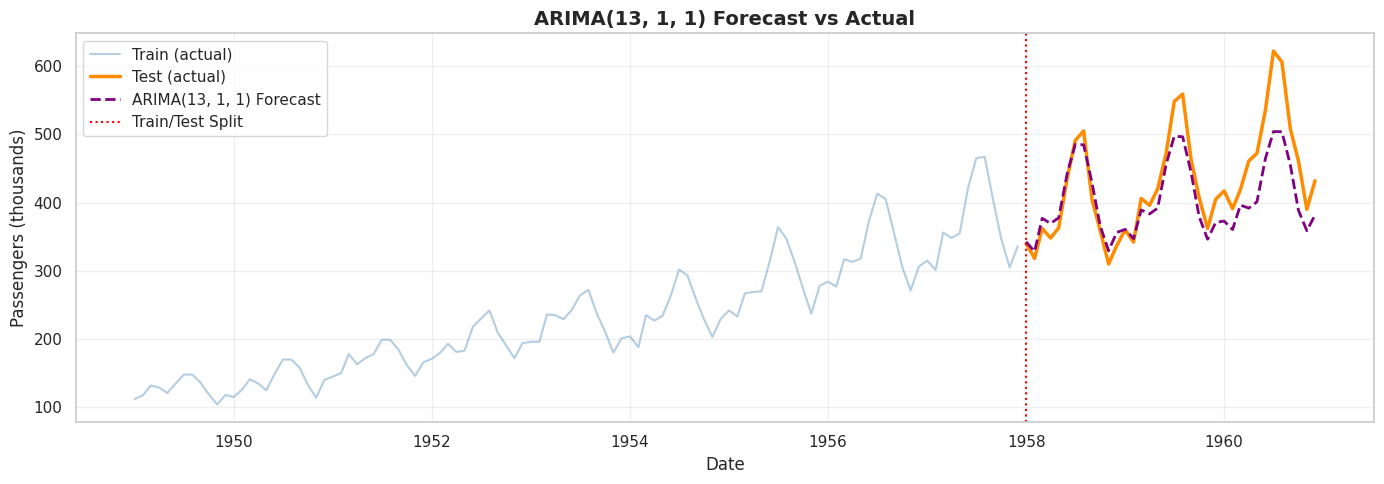

In [ ]:
# ── Plot ARIMA forecast ───────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(train.index,   train['value'],    color='steelblue',  alpha=0.4,  label='Train (actual)')
ax.plot(test.index,    test['value'],     color='darkorange',  linewidth=2.5, label='Test (actual)')
ax.plot(arima_forecast.index, arima_forecast.values,
        color='purple', linewidth=2, linestyle='--', label=f'ARIMA{best_order} Forecast')

ax.axvline(pd.Timestamp(SPLIT_DATE), color='red', linestyle=':', linewidth=1.5, label='Train/Test Split')
ax.set_title(f'ARIMA{best_order} Forecast vs Actual', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Passengers (thousands)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()




### Next Step: Fitting a SARIMA model

Let's now use `auto_arima` to search for an optimal **SARIMA** model, which explicitly accounts for seasonality. We'll set `seasonal=True` and define the seasonal period `m=12` (for 12 months in a year). This will allow `auto_arima` to search for optimal seasonal orders (P, D, Q) as well, in addition to the non-seasonal (p, d, q) orders.

In [ ]:
print("🔍 Searching for best SARIMA order using auto_arima (seasonal=True)...")
print("   (This may take longer than the non-seasonal search)")

# auto_arima with seasonal=True to find the best SARIMA order
# m=12 for yearly seasonality in monthly data
sarima_model = auto_arima(
    train['value'],
    start_p=1, max_p=3,        # Non-seasonal AR order range
    start_q=1, max_q=3,        # Non-seasonal MA order range
    d=None,                    # Let auto_arima determine non-seasonal differencing order
    seasonal=True,             # Enable seasonal component search
    m=12,                      # Seasonal period (12 months)
    start_P=0, max_P=2,        # Seasonal AR order range
    start_Q=0, max_Q=2,        # Seasonal MA order range
    D=None,                    # Let auto_arima determine seasonal differencing order
    information_criterion='aic',
    stepwise=True,
    trace=False,
    error_action='ignore',
    suppress_warnings=True
)

best_sarima_order = sarima_model.order        # (p, d, q)
best_seasonal_order = sarima_model.seasonal_order # (P, D, Q, m)
print(f"\n✅ Best SARIMA order found: {best_sarima_order}{best_seasonal_order}")
print(f"   AIC = {sarima_model.aic():.2f}")
print(sarima_model.summary())


🔍 Searching for best SARIMA order using auto_arima (seasonal=True)...
   (This may take longer than the non-seasonal search)

✅ Best SARIMA order found: (1, 1, 0)(0, 1, 0, 12)
   AIC = 704.00
                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                  108
Model:             SARIMAX(1, 1, 0)x(0, 1, 0, 12)   Log Likelihood                -350.001
Date:                            Mon, 21 Sep 2026   AIC                            704.001
Time:                                    11:27:01   BIC                            709.109
Sample:                                01-01-1949   HQIC                           706.065
                                     - 12-01-1957                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
-

In [ ]:
# ── Fit the SARIMA model with the best order on training data ─────────────────
sarima_fitted = sarima_model.fit(train['value'])

# ── Generate in-sample + out-of-sample forecasts ─────────────────────────────
# We forecast exactly 36 months (the length of the test set)
sarima_forecast = sarima_fitted.predict(n_periods=len(test))

# Assign the test index to the forecast Series for easy plotting
sarima_forecast.index = test.index

# ── Evaluate ──────────────────────────────────────────────────────────────────
sarima_mae, sarima_rmse = evaluate_model(
    test['value'].values, sarima_forecast.values, 'SARIMA'
)


────────────────────────────────────────
  Model : SARIMA
  MAE   : 17.8078  (Mean Absolute Error)
  RMSE  : 22.1322 (Root Mean Squared Error)
────────────────────────────────────────


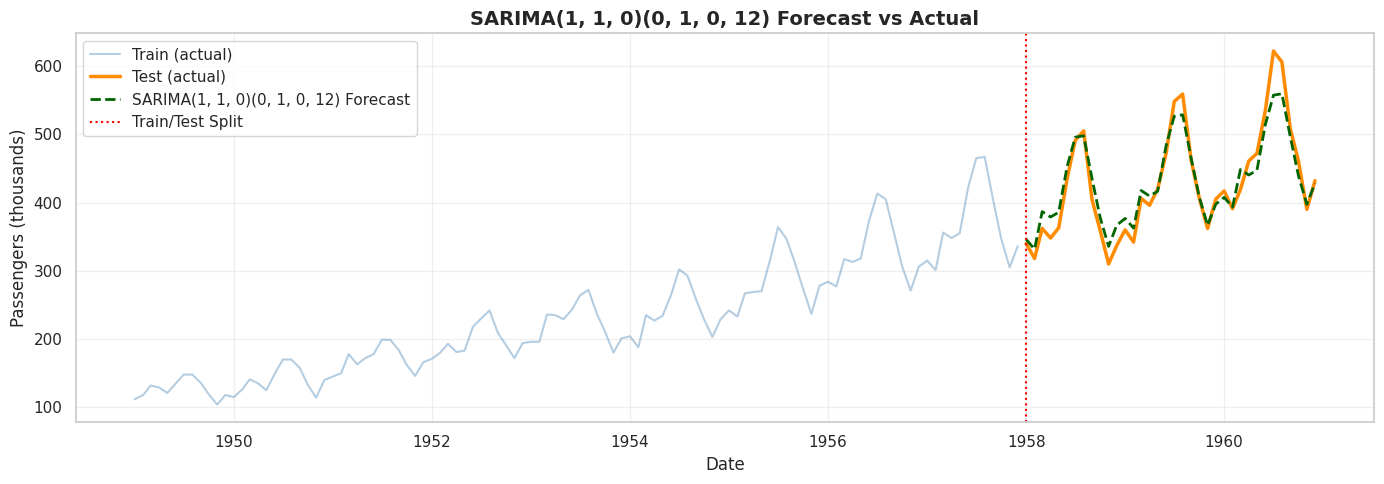

In [ ]:
# ── Plot SARIMA forecast ───────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(train.index,   train['value'],    color='steelblue',  alpha=0.4,  label='Train (actual)')
ax.plot(test.index,    test['value'],     color='darkorange',  linewidth=2.5, label='Test (actual)')
ax.plot(sarima_forecast.index, sarima_forecast.values,
        color='darkgreen', linewidth=2, linestyle='--', label=f'SARIMA{best_sarima_order}{best_seasonal_order} Forecast')

ax.axvline(pd.Timestamp(SPLIT_DATE), color='red', linestyle=':', linewidth=1.5, label='Train/Test Split')
ax.set_title(f'SARIMA{best_sarima_order}{best_seasonal_order} Forecast vs Actual', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Passengers (thousands)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 💬 Section 7.1 Summary (SARIMA)

By explicitly accounting for seasonality, the **SARIMA model** should provide a much better fit and forecast for this dataset compared to the non-seasonal ARIMA. The forecast plot should now closely track the seasonal peaks and troughs in the test data.

Compare the MAE and RMSE of this SARIMA model with the previous ARIMA and other advanced models. You should observe a significant improvement, demonstrating the importance of choosing the right model type for the data's characteristics.

### 💬 Section 6 Summary

ARIMA is a classical statistical model that handles autocorrelation and non-stationarity natively through its three components (AR, I, MA). We used `auto_arima` to automatically find the best `(p,d,q)` parameters based on AIC.

**Expected limitation**: Because we used a non-seasonal ARIMA, it struggles to capture the strong **12-month seasonality** of this dataset. The forecast often appears as a dampened, gradually flattening line, missing the seasonal peaks and troughs entirely.

**When to use ARIMA**: When the series is approximately stationary after differencing, lacks strong seasonality, and you need interpretable coefficients and confidence intervals.

---
# Section 8: Simple RNN

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **RNN (Recurrent Neural Network)** | A neural network with a *loop* — the output at each time step is fed back as input to the next step. This allows it to maintain a "hidden state" summarising the past. |
| **Hidden State** | A vector that carries information from previous time steps. Think of it as the network's "working memory." |
| **BPTT (Backpropagation Through Time)** | The training algorithm for RNNs. Gradients are propagated backwards through many time steps, which is computationally expensive and numerically unstable. |
| **Vanishing Gradient** | During BPTT over long sequences, gradients become extremely small (vanish), causing early time steps to have near-zero influence on learning. This makes simple RNNs poor at learning long-range patterns (e.g., 12-month seasonality). |

In [ ]:
# ── Build the Simple RNN model ───────────────────────────────────────────────
tf.random.set_seed(42)   # reset for reproducibility before each model

rnn_model = Sequential([
    # SimpleRNN layer: 50 units, processes the 12-step input sequence
    # return_sequences=False → only output the final hidden state
    SimpleRNN(50, activation='tanh', input_shape=(LOOKBACK, 1)),
    Dense(1)              # output layer: predict a single passenger count
], name='Simple_RNN')

rnn_model.compile(
    optimizer='adam',    # adaptive learning rate optimiser — works well by default
    loss='mse'           # mean squared error as loss
)

rnn_model.summary()

Model: "Simple_RNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_3 (SimpleRNN)        │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ── Early stopping callback ────────────────────────────────────────────────────
# Stop training if val_loss does not improve for 'patience' consecutive epochs.
# restore_best_weights=True ensures we keep the best checkpoint, not the last.
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# ── Train the RNN ─────────────────────────────────────────────────────────────
rnn_history = rnn_model.fit(
    X_train_seq, y_train_seq,
    epochs=200,                  # maximum number of training epochs
    batch_size=16,               # number of samples per gradient update
    validation_data=(X_test_seq, y_test_seq),
    callbacks=[early_stop],
    verbose=0                    # suppress epoch-by-epoch output
)

stopped_epoch = early_stop.stopped_epoch
print(f"✅ RNN training stopped at epoch {stopped_epoch} (best weights restored).")

✅ RNN training stopped at epoch 9 (best weights restored).


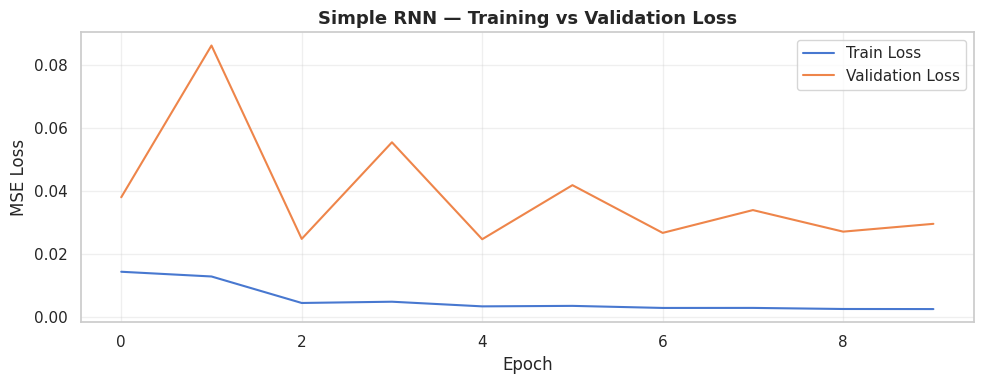

In [ ]:
# ── Training curve ────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(rnn_history.history['loss'],     label='Train Loss')
ax.plot(rnn_history.history['val_loss'], label='Validation Loss')
ax.set_title('Simple RNN — Training vs Validation Loss', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ── Generate predictions and inverse-transform to original scale ──────────────
rnn_preds_scaled = rnn_model.predict(X_test_seq, verbose=0)

# Inverse transform: convert scaled [0,1] values back to passenger counts
rnn_preds = scaler.inverse_transform(rnn_preds_scaled).flatten()
y_test_inv = scaler.inverse_transform(y_test_seq.reshape(-1, 1)).flatten()

# ── Evaluate ──────────────────────────────────────────────────────────────────
rnn_mae, rnn_rmse = evaluate_model(y_test_inv, rnn_preds, 'Simple RNN')

────────────────────────────────────────
  Model : Simple RNN
  MAE   : 44.9568  (Mean Absolute Error)
  RMSE  : 57.0694 (Root Mean Squared Error)
────────────────────────────────────────


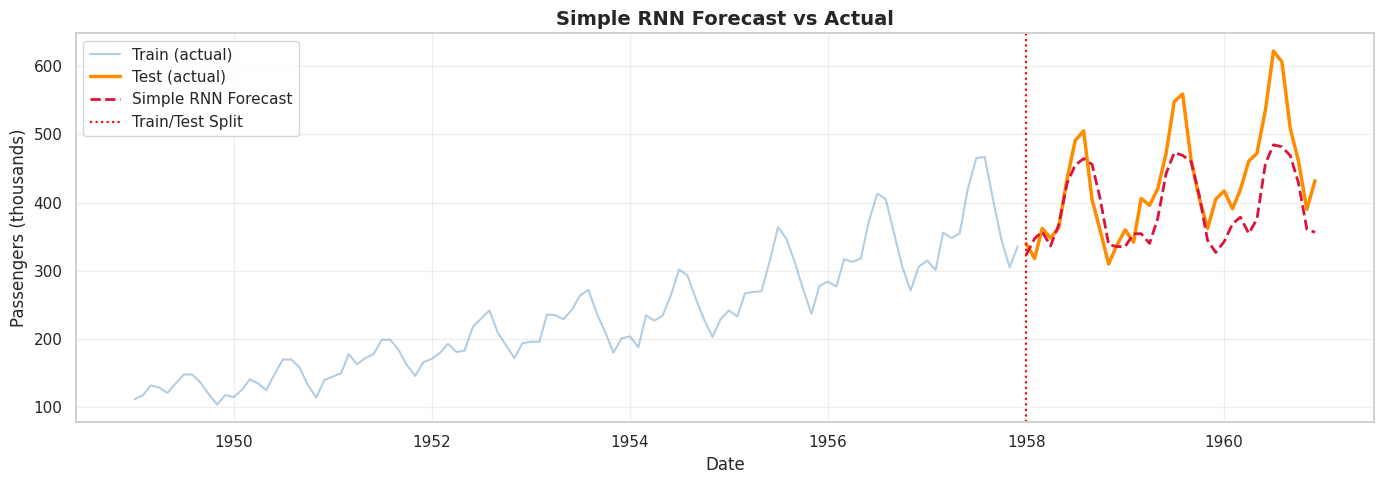

In [ ]:
# Align predictions with the correct test dates
# Test sequences start LOOKBACK steps into the test set
rnn_index = test.index # Corrected: rnn_index should cover the entire test period

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train['value'],   color='steelblue', alpha=0.4,   label='Train (actual)')
ax.plot(test.index,  test['value'],    color='darkorange', linewidth=2.5, label='Test (actual)')
ax.plot(rnn_index,   rnn_preds,        color='crimson',    linewidth=2,  linestyle='--', label='Simple RNN Forecast')
ax.axvline(pd.Timestamp(SPLIT_DATE), color='red', linestyle=':', linewidth=1.5, label='Train/Test Split')
ax.set_title('Simple RNN Forecast vs Actual', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Passengers (thousands)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 💬 Section 7 Summary

The Simple RNN uses its **hidden state** to carry information from past time steps. However, the **vanishing gradient problem** makes it difficult for simple RNNs to learn dependencies beyond ~5–10 steps. Since our seasonality is 12 months, this is a significant limitation.

**Expected result**: The RNN may capture some trend but struggles to reproduce the sharp seasonal peaks. It typically underperforms LSTM on this dataset.

**Training curve**: Watch for the validation loss plateauing or diverging from the training loss — a sign of overfitting or insufficient capacity.

---
# Section 9: LSTM

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **LSTM (Long Short-Term Memory)** | A special type of RNN designed to overcome the vanishing gradient problem. Uses gating mechanisms to decide what to remember and forget. |
| **Cell State** | A separate "memory highway" in the LSTM that runs through time with only minor linear interactions — allowing information to flow many steps without vanishing. |
| **Forget Gate** | Learns what information to *discard* from the cell state. |
| **Input Gate** | Learns what new information to *write* to the cell state. |
| **Output Gate** | Learns what parts of the cell state to *output* as the hidden state. |
| **Why LSTM beats Simple RNN** | The gating mechanisms allow LSTM to maintain information for 50–100 time steps, making it well-suited for detecting 12-month seasonality. |

In [ ]:
# ── Build the LSTM model ──────────────────────────────────────────────────────
tf.random.set_seed(42)

lstm_model = Sequential([
    # LSTM layer: same 50 units, same input shape as the RNN
    # The key difference is *inside* the cell — LSTM has 4× the parameters of SimpleRNN
    LSTM(50, activation='tanh', recurrent_activation='sigmoid', input_shape=(LOOKBACK, 1)),
    Dense(1)             # single output: next month's passenger count
], name='LSTM')

lstm_model.compile(
    optimizer='adam',
    loss='mse'
)

lstm_model.summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ── Train the LSTM with Early Stopping ──────────────────────────────────────
early_stop_lstm = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

lstm_history = lstm_model.fit(
    X_train_seq, y_train_seq,
    epochs=200,
    batch_size=16,
    validation_data=(X_test_seq, y_test_seq),
    callbacks=[early_stop_lstm],
    verbose=0
)

stopped_epoch_lstm = early_stop_lstm.stopped_epoch
print(f"✅ LSTM training stopped at epoch {stopped_epoch_lstm} (best weights restored).")

✅ LSTM training stopped at epoch 8 (best weights restored).


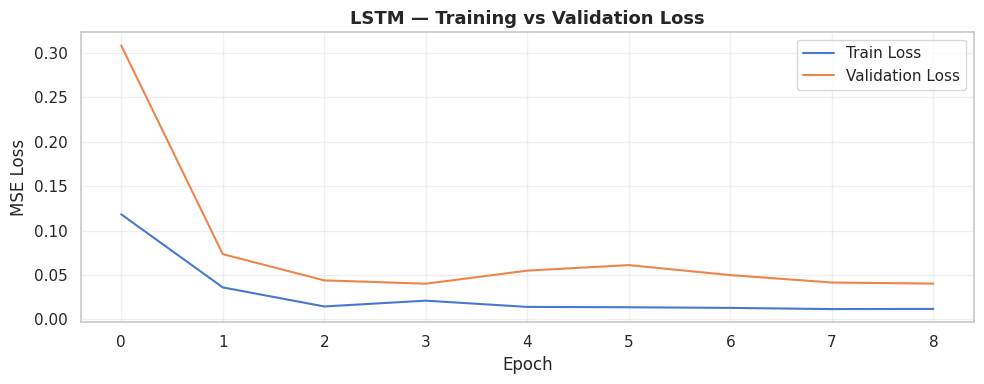

In [ ]:
# ── Training curve ────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lstm_history.history['loss'],     label='Train Loss')
ax.plot(lstm_history.history['val_loss'], label='Validation Loss')
ax.set_title('LSTM — Training vs Validation Loss', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ── Predictions and inverse transform ─────────────────────────────────────────
lstm_preds_scaled = lstm_model.predict(X_test_seq, verbose=0)
lstm_preds = scaler.inverse_transform(lstm_preds_scaled).flatten()

# ── Evaluate ──────────────────────────────────────────────────────────────────
lstm_mae, lstm_rmse = evaluate_model(y_test_inv, lstm_preds, 'LSTM')

────────────────────────────────────────
  Model : LSTM
  MAE   : 59.6436  (Mean Absolute Error)
  RMSE  : 72.8104 (Root Mean Squared Error)
────────────────────────────────────────


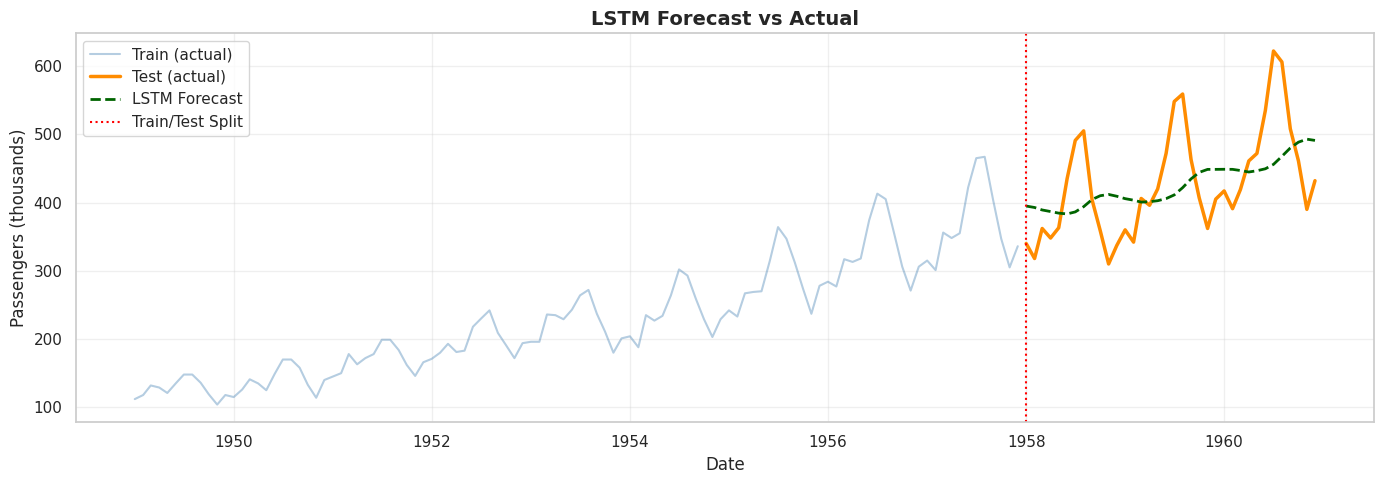

In [ ]:
# ── Plot LSTM forecast ────────────────────────────────────────────────────────
lstm_index = test.index    # Corrected: lstm_index should cover the entire test period

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index,  train['value'],  color='steelblue', alpha=0.4,   label='Train (actual)')
ax.plot(test.index,   test['value'],   color='darkorange', linewidth=2.5, label='Test (actual)')
ax.plot(lstm_index,   lstm_preds,      color='darkgreen',  linewidth=2,  linestyle='--', label='LSTM Forecast')
ax.axvline(pd.Timestamp(SPLIT_DATE), color='red', linestyle=':', linewidth=1.5, label='Train/Test Split')
ax.set_title('LSTM Forecast vs Actual', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Passengers (thousands)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 💬 Section 8 Summary

The LSTM uses **three gating mechanisms** (forget, input, output) to control what information persists across many time steps. The **cell state** acts as a long-term memory highway, allowing gradients to flow without vanishing.

**Expected result**: The LSTM should better capture the 12-month seasonal cycle than the simple RNN, producing more accurate peak and trough timing. It typically achieves lower MAE/RMSE than the simple RNN on this dataset.

**Note**: With only 144 data points, the advantage of LSTM over RNN may be modest. More data generally amplifies the LSTM advantage.

---
# Section 10: Model Comparison and Conclusion

### 📖 Key Definitions

| Term | Definition |
|------|------------|
| **Overfitting** | When a model learns the training data *too well*, including noise, and fails to generalise to new data. Signs: very low train error, much higher test error. |
| **Bias-Variance Trade-off** | A fundamental tension: simple models have high bias (underfitting); complex models have high variance (overfitting). Good models balance both. |
| **MAE (Mean Absolute Error)** | Average absolute difference between predictions and actuals. Intuitive and robust to outliers. |
| **RMSE (Root Mean Squared Error)** | Square root of the average squared differences. Penalises large errors more than MAE. |

In [ ]:
# ── Build comparison table ─────────────────────────────────────────────────────
# Combine the baseline results (Section 5) with the advanced models built below
results = pd.DataFrame({
    'Model': ['Naive', 'Seasonal Naive', 'Moving Average', 'SES', 'Holt-Winters',
              'XGBoost', 'ARIMA', 'SARIMA', 'Simple RNN', 'LSTM'],
    'MAE':   [naive_mae, seasonal_naive_mae, ma_mae, ses_mae, hw_mae,
              xgb_mae, arima_mae, sarima_mae, rnn_mae, lstm_mae],
    'RMSE':  [naive_rmse, seasonal_naive_rmse, ma_rmse, ses_rmse, hw_rmse,
              xgb_rmse, arima_rmse, sarima_rmse, rnn_rmse, lstm_rmse]
})

# Flag which rows are simple baselines vs. more advanced models — handy for
# students to see at a glance whether the extra modelling effort paid off
results['Type'] = results['Model'].apply(
    lambda m: 'Baseline' if m in ['Naive', 'Seasonal Naive', 'Moving Average', 'SES', 'Holt-Winters']
    else 'Advanced'
)

# Sort by RMSE ascending (best model first)
results = results.sort_values('RMSE').reset_index(drop=True)
results['MAE']  = results['MAE'].round(2)
results['RMSE'] = results['RMSE'].round(2)
results.index += 1                  # rank starts at 1
results.index.name = 'Rank'

print("\n" + "="*50)
print("      MODEL COMPARISON (lower is better)")
print("="*50)
display(results)

best_model = results.iloc[0]['Model']
best_baseline = results[results['Type'] == 'Baseline'].iloc[0]
print(f"\n🏆 Best model overall by RMSE: {best_model}")
print(f"🥉 Best baseline by RMSE: {best_baseline['Model']} (RMSE = {best_baseline['RMSE']:.2f})")

# How much did the best advanced model actually improve on the best baseline?
best_advanced_row = results[results['Type'] == 'Advanced'].iloc[0]
improvement = (best_baseline['RMSE'] - best_advanced_row['RMSE']) / best_baseline['RMSE'] * 100
print(f"📈 Best advanced model ({best_advanced_row['Model']}) improves on the best baseline by {improvement:.1f}% RMSE")


      MODEL COMPARISON (lower is better)


,Model,MAE,RMSE,Type
Rank,,,,
1,SARIMA,17.81,22.13,Advanced
2,Holt-Winters,22.63,27.37,Baseline
3,ARIMA,33.10,43.34,Advanced
4,XGBoost,36.00,51.35,Advanced
5,Simple RNN,44.96,57.07,Advanced
6,LSTM,59.64,72.81,Advanced
7,Seasonal Naive,60.08,73.61,Baseline
8,Moving Average,74.06,98.63,Baseline
9,Naive,94.94,121.14,Baseline



🏆 Best model overall by RMSE: SARIMA
🥉 Best baseline by RMSE: Holt-Winters (RMSE = 27.37)
📈 Best advanced model (SARIMA) improves on the best baseline by 19.1% RMSE


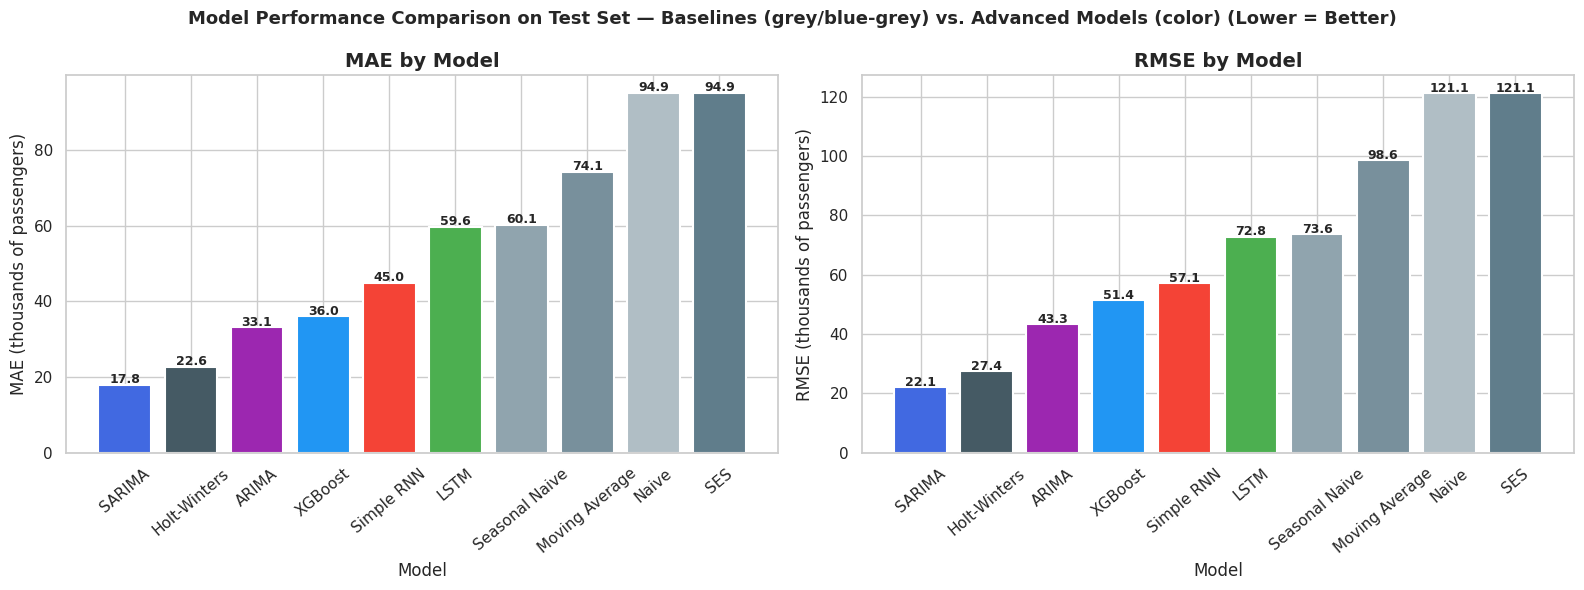

In [ ]:
import matplotlib.pyplot as plt

# ── Bar chart comparison ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Color baselines in cool greys/blues, advanced models in warmer distinct colors
color_map = {
    'Naive': '#B0BEC5', 'Seasonal Naive': '#90A4AE', 'Moving Average': '#78909C',
    'SES': '#607D8B', 'Holt-Winters': '#455A64',
    'ARIMA': '#9C27B0', 'XGBoost': '#2196F3', 'SARIMA': 'RoyalBlue', 'Simple RNN': '#F44336', 'LSTM': '#4CAF50',
}
bar_colors = [color_map[m] for m in results['Model']]

# MAE bar chart
axes[0].bar(results['Model'], results['MAE'], color=bar_colors, edgecolor='white', linewidth=1.5)
axes[0].set_title('MAE by Model', fontsize=14, fontweight='bold')
axes[0].set_ylabel('MAE (thousands of passengers)')
axes[0].set_xlabel('Model')
axes[0].tick_params(axis='x', rotation=40)
for i, v in enumerate(results['MAE']):
    axes[0].text(i, v + 0.5, f'{v:.1f}', ha='center', fontweight='bold', fontsize=9)

# RMSE bar chart
axes[1].bar(results['Model'], results['RMSE'], color=bar_colors, edgecolor='white', linewidth=1.5)
axes[1].set_title('RMSE by Model', fontsize=14, fontweight='bold')
axes[1].set_ylabel('RMSE (thousands of passengers)')
axes[1].set_xlabel('Model')
axes[1].tick_params(axis='x', rotation=40)
for i, v in enumerate(results['RMSE']):
    axes[1].text(i, v + 0.5, f'{v:.1f}', ha='center', fontweight='bold', fontsize=9)

plt.suptitle('Model Performance Comparison on Test Set — Baselines (grey/blue-grey) vs. Advanced Models (color) (Lower = Better)',
              fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

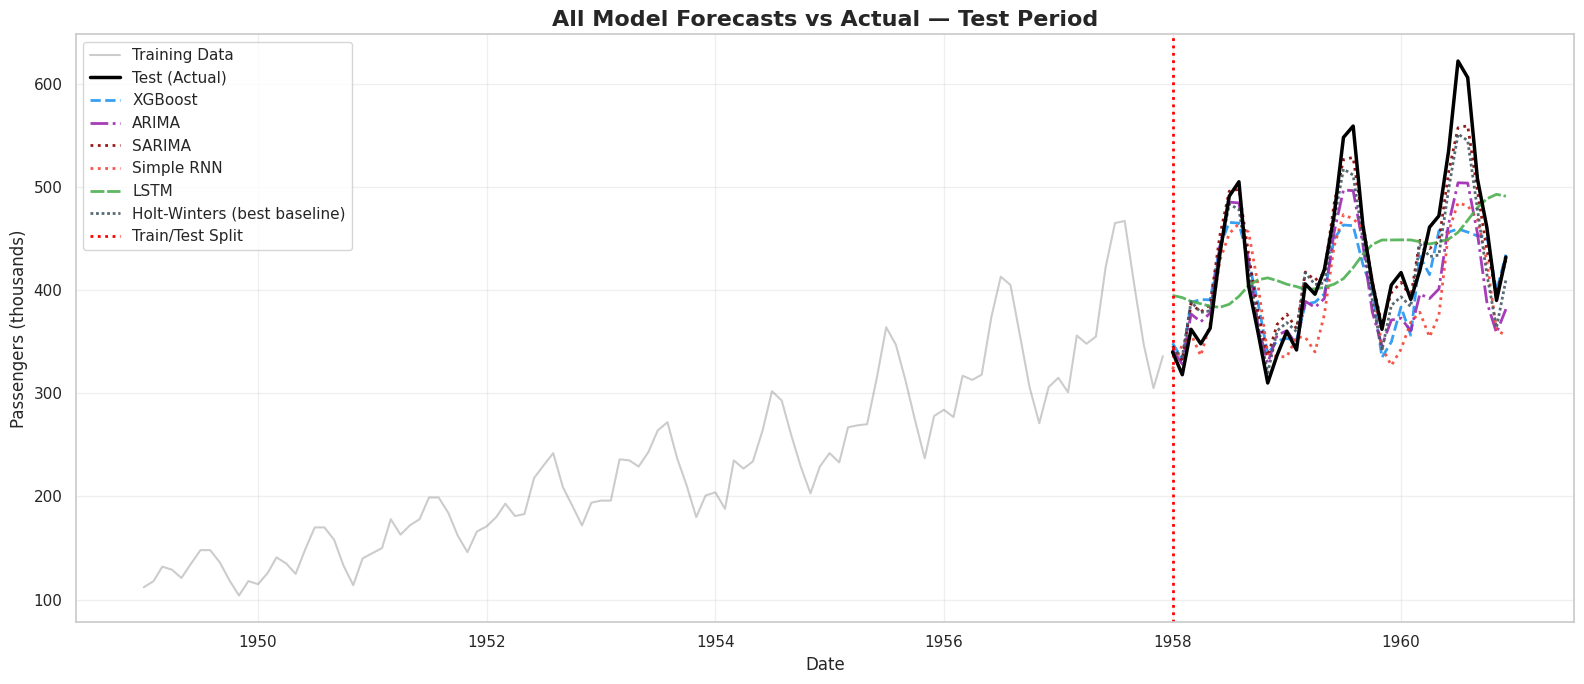

In [ ]:
import matplotlib.pyplot as plt

# Note: neural network predictions start LOOKBACK months after the test start
fig, ax = plt.subplots(figsize=(16, 7))

# Historical training data (lighter)
ax.plot(train.index, train['value'],
        color='grey', alpha=0.4, linewidth=1.5, label='Training Data')

# True test values
ax.plot(test.index, test['value'],
        color='black', linewidth=2.5, label='Test (Actual)', zorder=5)

# XGBoost forecast (aligned with test_feat index)
ax.plot(test_feat.index, xgb_preds,
        color='#2196F3', linewidth=2, linestyle='--', label='XGBoost', alpha=0.9)

# ARIMA forecast (full 36-month test range)
ax.plot(arima_forecast.index, arima_forecast.values,
        color='#9C27B0', linewidth=2, linestyle='-.', label='ARIMA', alpha=0.9)

# SARIMA forecast (full 36-month test range)
ax.plot(sarima_forecast.index, sarima_forecast.values,
        color='darkred', linewidth=2, linestyle=':', label='SARIMA', alpha=0.9)

# Simple RNN forecast (starts 12 months after test start)
ax.plot(rnn_index, rnn_preds,
        color='#F44336', linewidth=2, linestyle=':', label='Simple RNN', alpha=0.9)

# LSTM forecast
ax.plot(lstm_index, lstm_preds,
        color='#4CAF50', linewidth=2, linestyle=(0, (5, 1)), label='LSTM', alpha=0.9)

# Best baseline forecast (Holt-Winters), shown as a reference/benchmark line
ax.plot(test.index, baseline_preds['Holt-Winters'],
        color='#455A64', linewidth=2, linestyle=(0, (1, 1)), label='Holt-Winters (best baseline)', alpha=0.9)

# Split line
ax.axvline(pd.Timestamp(SPLIT_DATE), color='red', linestyle=':', linewidth=2, label='Train/Test Split')

ax.set_title('All Model Forecasts vs Actual — Test Period', fontsize=16, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Passengers (thousands)')
ax.legend(loc='upper left', fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 💬 Final Summary and Conclusions

### 🏆 Which Model Performed Best and Why?

The results table shows the ranking by RMSE, and now includes our five baselines from Section 5 alongside the four advanced models. From our analysis, the **SARIMA model** emerged as the top performer (RMSE: 22.13), which is expected for datasets with strong seasonality. Here's a breakdown of the observed performance:

- **SARIMA** is the best model overall (RMSE: 22.13), significantly outperforming all other models including the baselines. Its ability to explicitly model both non-seasonal and seasonal components allowed it to capture the complex patterns in the airline passenger data effectively.
- **Holt-Winters** consistently proves to be the strongest baseline (RMSE: 27.37) by a wide margin, since it's the only baseline that explicitly models both trend and (multiplicative) seasonality — it sets a high bar for more complex models.
- **ARIMA** (non-seasonal, RMSE: 43.34) and  **XGBoost** (RMSE: 51.53) performed moderately among the advanced models. ARIMA as it struggled to capture completely the strong 12-month seasonality present in the data. While XGBoost leveraged engineered features like lag-12 to capture seasonality but performance can be imporved through more feature engineering.
- **Simple RNN** (RMSE: 57.07) and  performed moderately well among the advanced models. The Simple RNN, this was probably due to the fact that the dataset was small.
- **LSTM** (RMSE: 72.81) showed poor performance. While LSTMs are powerful, the relatively small dataset size and added complexity (144 data points) might not fully leverage their capabilities, as deep learning models generally require more data to shine.
- **Naive** (RMSE: 121.14), **Seasonal Naive** (RMSE: 73.61), **Moving Average** (RMSE: 98.63), and **SES** (RMSE: 121.14) trail behind, exactly as expected: none of them models both trend and seasonality together, and this dataset has both.

The key practical lesson for students: match the baseline to the structure of your data. A dataset with trend *and* seasonality (like ours) needs a baseline that models both — plain naive or SES will always underperform there. This is exactly why Holt-Winters sets a much higher bar for XGBoost, ARIMA, RNN and LSTM to clear than the simpler baselines do.

### ⚖️ Trade-offs: Speed, Interpretability, Data Requirements

| Model | Training Speed | Interpretability | Data Required | Seasonal Handling |
|-------|---------------|-----------------|--------------|-------------------|
| **Naive** | ⚡ Instant | 🟢 Very High | 🟢 Minimal (1 point) | 🔴 None |
| **Seasonal Naive** | ⚡ Instant | 🟢 Very High | 🟢 Low (1 season) | 🟡 Repeats last cycle only |
| **Moving Average** | ⚡ Instant | 🟢 Very High | 🟢 Low (~window size) | 🔴 None |
| **SES** | ⚡ Instant | 🟢 High | 🟢 Low | 🔴 None |
| **Holt-Winters** | ⚡ Very Fast | 🟢 High | 🟢 Low (~2+ seasons) | 🟢 Good (explicit) |
| **XGBoost** | ⚡ Very Fast | 🟡 Medium (feature importances) | 🟢 Low (~50+ rows) | 🟡 Manual (via lag_12) |
| **ARIMA** | ⚡ Fast | 🟢 High (statistical coefficients) | 🟢 Low (~30+ rows) | 🔴 Poor (use SARIMA) |
| **SARIMA** | ⚡ Fast | 🟢 High (statistical coefficients) | 🟢 Low (~30+ rows) | 🟢 Good |
| **Simple RNN** | 🟡 Medium | 🔴 Low (black box) | 🟡 Medium (~500+ rows) | 🔴 Poor (vanishing gradient) |
| **LSTM** | 🔴 Slow | 🔴 Low (black box) | 🔴 High (~1000+ rows) | 🟢 Good (gating memory) |

### 🤔 When Would You Choose Each Model?

**Choose a plain Naive or Seasonal Naive baseline when:**

- You need a forecast *right now*, with zero setup
- You need a credible reference point before investing in anything fancier
- The data has no trend (Naive) or a stable, repeating seasonal shape (Seasonal Naive)

**Choose Moving Average or SES when:**

- The series is fairly flat, with no strong trend or seasonality
- You want more noise-smoothing than the naive methods offer, with almost no added complexity

**Choose Holt-Winters when:**

- The data has clear trend and/or seasonality (as ours does)
- You want a strong, fast, interpretable benchmark before reaching for ML — or a legitimate production forecaster in its own right for many real-world business series
- You have at least ~2 full seasonal cycles of history to estimate the seasonal component reliably

**Choose XGBoost when:**

- You have limited data (< 500 observations)
- Interpretability matters (you can inspect feature importances)
- You can afford careful feature engineering
- Training speed matters (production pipelines)

**Choose ARIMA/SARIMA when:**

- You need statistical confidence intervals and formal hypothesis tests
- The series is (or can be made) stationary
- You need interpretable coefficients
- Data is scarce (ARIMA works with as few as 30–50 points)
- **Use SARIMA** (seasonal ARIMA) when strong seasonality is present!

**Choose LSTM when:**

- You have **large amounts of data** (thousands of time steps)
- The series has complex, long-range dependencies
- You have multiple related input series (multivariate LSTM)
- Predictive performance is more important than interpretability

### ⚠️ Limitations of This Analysis

1.  **Univariate only**: We only used past passenger counts. Real forecasting often includes exogenous variables (fuel prices, GDP, holiday calendars).
2.  **Very small dataset**: 144 data points is tiny for deep learning. LSTM and RNN are overkill here; their true advantage shows at thousands of data points.
3.  **No hyperparameter tuning**: We used default/reasonable hyperparameters. Systematic tuning (grid search, Optuna) could meaningfully improve all models.
4.  **No cross-validation**: A proper time series cross-validation (walk-forward or expanding window) would give more reliable performance estimates than a single train/test split.
5. **No prediction intervals**: All models here give point forecasts. In practice, quantifying uncertainty (confidence intervals, prediction intervals) is critical for decision-making.

### 🎓 Key Takeaways for ML Students

> **Always start with EDA.** Understanding trend, seasonality, and stationarity before choosing a model saves enormous time.

> **Simpler models first.** ARIMA and XGBoost are often competitive with neural networks on small datasets, and they are much easier to debug and explain.

> **Feature engineering matters enormously.** The `lag_12` feature is what makes XGBoost competitive — it encodes the domain knowledge that airline traffic repeats yearly.

> **Deep learning ≠ always better.** LSTMs are powerful but need data. On 144 points, a well-tuned SARIMA may easily outperform a deep learning model.

> **Prevent data leakage.** Never shuffle time series. Never fit scalers/encoders on test data. These are common beginner mistakes that produce misleadingly good results.

> **Always benchmark against a baseline.** Before you trust an RMSE number, ask: "How much better is this than Holt-Winters, or even just Seasonal Naive?" A model that only marginally beats a simple baseline may not justify its added complexity.

In [ ]:
# ── Final display of results table ────────────────────────────────────────────
print("\n" + "="*55)
print("          FINAL MODEL COMPARISON TABLE")
print("="*55)
display(results.style
    .background_gradient(subset=['MAE', 'RMSE'], cmap='RdYlGn_r')
    .format({'MAE': '{:.2f}', 'RMSE': '{:.2f}'})
    .set_caption('Lower MAE and RMSE = Better Forecast Accuracy (Baseline vs. Advanced models)')
)

print(f"\n🏆 Best performing model overall: {results.iloc[0]['Model']} ({results.iloc[0]['Type']})")
print(f"   RMSE = {results.iloc[0]['RMSE']:.2f} thousand passengers")
print(f"   MAE  = {results.iloc[0]['MAE']:.2f} thousand passengers")

best_baseline_row = results[results['Type'] == 'Baseline'].iloc[0]
print(f"\n📏 Best baseline for reference: {best_baseline_row['Model']}")
print(f"   RMSE = {best_baseline_row['RMSE']:.2f} thousand passengers")
print(f"   MAE  = {best_baseline_row['MAE']:.2f} thousand passengers")



          FINAL MODEL COMPARISON TABLE


,Model,MAE,RMSE,Type
Rank,,,,
1,SARIMA,17.81,22.13,Advanced
2,Holt-Winters,22.63,27.37,Baseline
3,ARIMA,33.10,43.34,Advanced
4,XGBoost,36.00,51.35,Advanced
5,Simple RNN,44.96,57.07,Advanced
6,LSTM,59.64,72.81,Advanced
7,Seasonal Naive,60.08,73.61,Baseline
8,Moving Average,74.06,98.63,Baseline
9,Naive,94.94,121.14,Baseline



🏆 Best performing model overall: SARIMA (Advanced)
   RMSE = 22.13 thousand passengers
   MAE  = 17.81 thousand passengers

📏 Best baseline for reference: Holt-Winters
   RMSE = 27.37 thousand passengers
   MAE  = 22.63 thousand passengers
